In [1]:
# ============================================================
# CARDIOSAM-MEM — STEP 1: CAMUS DATASET INSPECTION
# ============================================================

import os
import glob
import numpy as np

CAMUS_ROOT = (
    "/kaggle/input/datasets/mykcs01/"
    "camus-public-20250702/CAMUS_public/database_nifti"
)

# ------------------------------------------------------------
# 1. Basic dataset structure
# ------------------------------------------------------------
patients = sorted(glob.glob(os.path.join(CAMUS_ROOT, "patient*")))

print("=" * 70)
print("CAMUS DATASET INSPECTION")
print("=" * 70)
print("Root:", CAMUS_ROOT)
print("Total patient folders:", len(patients))

print("\nFirst 10 patients:")
for p in patients[:10]:
    print(" ", os.path.basename(p))

# ------------------------------------------------------------
# 2. Show files from several patients
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("FILES IN FIRST 3 PATIENTS")
print("=" * 70)

for patient_dir in patients[:3]:
    print(f"\n[{os.path.basename(patient_dir)}]")
    for f in sorted(os.listdir(patient_dir)):
        print("  ", f)

# ------------------------------------------------------------
# 3. Count filename patterns
# ------------------------------------------------------------
all_files = glob.glob(
    os.path.join(CAMUS_ROOT, "patient*", "*")
)

nii_files = [
    f for f in all_files
    if f.endswith(".nii") or f.endswith(".nii.gz")
]

print("\n" + "=" * 70)
print("FILE COUNTS")
print("=" * 70)

patterns = {
    "2CH_ED image": "_2CH_ED.nii",
    "2CH_ED mask": "_2CH_ED_gt.nii",
    "2CH_ES image": "_2CH_ES.nii",
    "2CH_ES mask": "_2CH_ES_gt.nii",
    "4CH_ED image": "_4CH_ED.nii",
    "4CH_ED mask": "_4CH_ED_gt.nii",
    "4CH_ES image": "_4CH_ES.nii",
    "4CH_ES mask": "_4CH_ES_gt.nii",
    "2CH sequence": "_2CH_sequence.nii",
    "4CH sequence": "_4CH_sequence.nii",
}

for name, suffix in patterns.items():
    count = sum(
        os.path.basename(f).endswith(suffix)
        for f in nii_files
    )
    print(f"{name:20s}: {count}")

# ------------------------------------------------------------
# 4. Install/import nibabel if required
# ------------------------------------------------------------
try:
    import nibabel as nib
except ImportError:
    !pip -q install nibabel
    import nibabel as nib

# ------------------------------------------------------------
# 5. Inspect one patient numerically
# ------------------------------------------------------------
sample_patient = patients[0]
sample_files = sorted(
    glob.glob(os.path.join(sample_patient, "*.nii*"))
)

print("\n" + "=" * 70)
print("SAMPLE NIFTI CONTENT")
print("=" * 70)

for f in sample_files:
    img = nib.load(f)
    arr = img.get_fdata()

    print("\nFile:", os.path.basename(f))
    print("Shape:", arr.shape)
    print("dtype:", arr.dtype)
    print("min/max:", float(arr.min()), float(arr.max()))

    if "_gt" in os.path.basename(f):
        print("Mask unique values:", np.unique(arr))

# ------------------------------------------------------------
# 6. Search all GT masks for label values
# ------------------------------------------------------------
gt_files = [
    f for f in nii_files
    if "_gt" in os.path.basename(f)
]

global_labels = set()

for f in gt_files:
    arr = nib.load(f).get_fdata()
    global_labels.update(np.unique(arr).astype(int).tolist())

print("\n" + "=" * 70)
print("MASK LABEL CHECK")
print("=" * 70)

print("Number of GT files:", len(gt_files))
print("All label values found:", sorted(global_labels))

# ------------------------------------------------------------
# 7. Check image-mask shape matching
# ------------------------------------------------------------
problems = []

for gt_path in gt_files:
    image_path = gt_path.replace("_gt.nii.gz", ".nii.gz")
    image_path = image_path.replace("_gt.nii", ".nii")

    if not os.path.exists(image_path):
        problems.append(
            ("missing image", gt_path, image_path)
        )
        continue

    gt_shape = nib.load(gt_path).shape
    image_shape = nib.load(image_path).shape

    if gt_shape != image_shape:
        problems.append(
            ("shape mismatch", gt_path, gt_shape, image_shape)
        )

print("\nImage/mask problems:", len(problems))

for x in problems[:10]:
    print(x)

# ------------------------------------------------------------
# 8. Sequence information
# ------------------------------------------------------------
sequence_files = [
    f for f in nii_files
    if "sequence" in os.path.basename(f).lower()
]

sequence_shapes = []

for f in sequence_files[:20]:
    sequence_shapes.append(
        (os.path.basename(f), nib.load(f).shape)
    )

print("\n" + "=" * 70)
print("SEQUENCE EXAMPLES")
print("=" * 70)

for name, shape in sequence_shapes:
    print(name, "->", shape)

print("\nInspection complete.")

CAMUS DATASET INSPECTION
Root: /kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti
Total patient folders: 500

First 10 patients:
  patient0001
  patient0002
  patient0003
  patient0004
  patient0005
  patient0006
  patient0007
  patient0008
  patient0009
  patient0010

FILES IN FIRST 3 PATIENTS

[patient0001]
   Info_2CH.cfg
   Info_4CH.cfg
   MANDATORY_CITATION.md
   patient0001_2CH_ED.nii
   patient0001_2CH_ED_gt.nii
   patient0001_2CH_ES.nii
   patient0001_2CH_ES_gt.nii
   patient0001_2CH_half_sequence.nii
   patient0001_2CH_half_sequence_gt.nii
   patient0001_4CH_ED.nii
   patient0001_4CH_ED_gt.nii
   patient0001_4CH_ES.nii
   patient0001_4CH_ES_gt.nii
   patient0001_4CH_half_sequence.nii
   patient0001_4CH_half_sequence_gt.nii

[patient0002]
   Info_2CH.cfg
   Info_4CH.cfg
   MANDATORY_CITATION.md
   patient0002_2CH_ED.nii
   patient0002_2CH_ED_gt.nii
   patient0002_2CH_ES.nii
   patient0002_2CH_ES_gt.nii
   patient0002_2CH_half_sequence.nii
   patien

Image: /kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0001/patient0001_4CH_ED.nii
Mask : /kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0001/patient0001_4CH_ED_gt.nii
Image shape: (549, 389)
Mask shape : (549, 389)
Labels: [0. 1. 2. 3.]


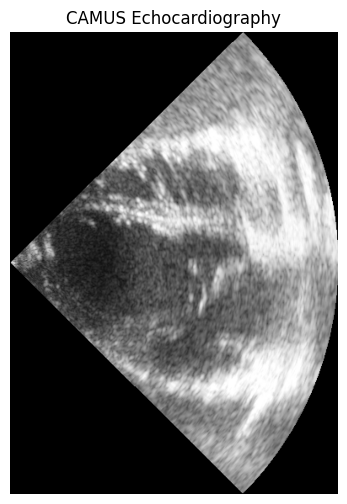

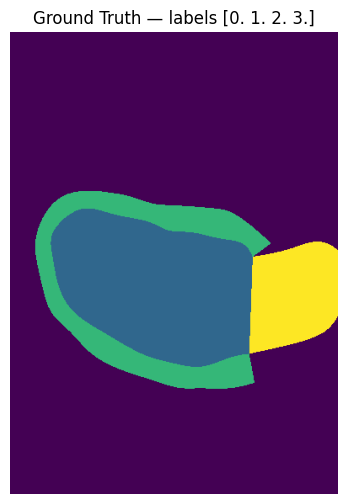

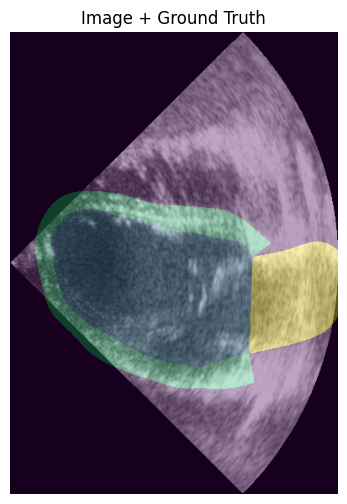

In [2]:
import matplotlib.pyplot as plt
import nibabel as nib
import glob
import os
import numpy as np

# Find first 4CH ED pair
gt_path = sorted(
    glob.glob(
        os.path.join(
            CAMUS_ROOT,
            "patient*",
            "*_4CH_ED_gt.nii*"
        )
    )
)[0]

img_path = gt_path.replace("_gt.nii.gz", ".nii.gz")
img_path = img_path.replace("_gt.nii", ".nii")

image = np.squeeze(nib.load(img_path).get_fdata())
mask  = np.squeeze(nib.load(gt_path).get_fdata())

print("Image:", img_path)
print("Mask :", gt_path)
print("Image shape:", image.shape)
print("Mask shape :", mask.shape)
print("Labels:", np.unique(mask))

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("CAMUS Echocardiography")
plt.axis("off")
plt.show()

plt.figure(figsize=(6, 6))
plt.imshow(mask)
plt.title(f"Ground Truth — labels {np.unique(mask)}")
plt.axis("off")
plt.show()

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.imshow(mask, alpha=0.35)
plt.title("Image + Ground Truth")
plt.axis("off")
plt.show()

In [3]:
# ================================================================
# CardioSAM-Mem
# PHASE 2 — CAMUS 4CH VIDEO DATASET PREPARATION
# ================================================================

import os
import glob
import random
import numpy as np
import nibabel as nib
import cv2
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------
# CONFIGURATION
# ------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CAMUS_ROOT = (
    "/kaggle/input/datasets/mykcs01/"
    "camus-public-20250702/CAMUS_public/database_nifti"
)

# Fast development configuration
N_PATIENTS = 200

N_TRAIN = 160
N_VAL   = 20
N_TEST  = 20

IMAGE_SIZE = 256

# CAMUS label used for LV cavity
LV_LABEL = 1

# ------------------------------------------------
# GET PATIENTS
# ------------------------------------------------

patients = sorted(
    glob.glob(os.path.join(CAMUS_ROOT, "patient*"))
)

print("Total CAMUS patients:", len(patients))

assert len(patients) == 500

# ------------------------------------------------
# RANDOM PATIENT-LEVEL SUBSET
# ------------------------------------------------

rng = np.random.default_rng(SEED)

indices = rng.permutation(len(patients))

selected_idx = indices[:N_PATIENTS]

selected_patients = [
    patients[i] for i in selected_idx
]

train_patients = selected_patients[:N_TRAIN]

val_patients = selected_patients[
    N_TRAIN:N_TRAIN + N_VAL
]

test_patients = selected_patients[
    N_TRAIN + N_VAL:
]

print("\nDevelopment subset")
print("-----------------------------")
print("Train patients :", len(train_patients))
print("Val patients   :", len(val_patients))
print("Test patients  :", len(test_patients))

assert len(train_patients) == 160
assert len(val_patients) == 20
assert len(test_patients) == 20

# Check leakage
assert len(
    set(train_patients) &
    set(val_patients)
) == 0

assert len(
    set(train_patients) &
    set(test_patients)
) == 0

assert len(
    set(val_patients) &
    set(test_patients)
) == 0

print("\n✓ No patient leakage")

Total CAMUS patients: 500

Development subset
-----------------------------
Train patients : 160
Val patients   : 20
Test patients  : 20

✓ No patient leakage


In [4]:
# ================================================================
# PREPROCESSING FUNCTIONS
# ================================================================

def normalize_echo(img):
    """
    Robust percentile normalization.
    Better than simply dividing by 255 because ultrasound
    intensity distributions differ between patients.
    """

    img = img.astype(np.float32)

    nonzero = img[img > 0]

    if len(nonzero) > 0:

        low = np.percentile(nonzero, 1)
        high = np.percentile(nonzero, 99)

        img = np.clip(img, low, high)

        if high > low:
            img = (img - low) / (high - low)

    else:
        img = np.zeros_like(img)

    return np.clip(img, 0, 1)


def resize_frame(img, size=256):

    return cv2.resize(
        img,
        (size, size),
        interpolation=cv2.INTER_LINEAR
    )


def resize_mask(mask, size=256):

    return cv2.resize(
        mask.astype(np.uint8),
        (size, size),
        interpolation=cv2.INTER_NEAREST
    )


def extract_lv_mask(mask):

    """
    Convert CAMUS multiclass mask into binary LV cavity mask.
    
    Background = 0
    LV cavity  = 1
    """

    return (mask == LV_LABEL).astype(np.uint8)


def load_camus_4ch_sequence(patient_dir):

    patient_id = os.path.basename(patient_dir)

    image_path = os.path.join(
        patient_dir,
        f"{patient_id}_4CH_half_sequence.nii"
    )

    mask_path = os.path.join(
        patient_dir,
        f"{patient_id}_4CH_half_sequence_gt.nii"
    )

    if not os.path.exists(image_path):
        return None

    if not os.path.exists(mask_path):
        return None

    images = nib.load(image_path).get_fdata()
    masks = nib.load(mask_path).get_fdata()

    assert images.shape == masks.shape

    processed_images = []
    processed_masks = []

    # Shape:
    # H x W x T

    for t in range(images.shape[-1]):

        frame = images[..., t]
        mask = masks[..., t]

        frame = normalize_echo(frame)

        lv_mask = extract_lv_mask(mask)

        frame = resize_frame(
            frame,
            IMAGE_SIZE
        )

        lv_mask = resize_mask(
            lv_mask,
            IMAGE_SIZE
        )

        processed_images.append(frame)
        processed_masks.append(lv_mask)

    images = np.stack(
        processed_images
    ).astype(np.float32)

    masks = np.stack(
        processed_masks
    ).astype(np.uint8)

    return {
        "patient_id": patient_id,
        "images": images,
        "masks": masks,
        "num_frames": images.shape[0]
    }

In [5]:
# ================================================================
# DATASET VALIDATION
# ================================================================

def validate_split(patient_list, split_name):

    records = []

    errors = []

    for patient_dir in patient_list:

        patient_id = os.path.basename(patient_dir)

        try:

            data = load_camus_4ch_sequence(
                patient_dir
            )

            if data is None:

                errors.append(
                    [patient_id, "Missing sequence"]
                )

                continue

            imgs = data["images"]
            masks = data["masks"]

            unique_labels = np.unique(masks)

            mask_areas = masks.sum(
                axis=(1,2)
            )

            empty_masks = int(
                np.sum(mask_areas == 0)
            )

            records.append({

                "split": split_name,

                "patient":
                    patient_id,

                "frames":
                    len(imgs),

                "height":
                    imgs.shape[1],

                "width":
                    imgs.shape[2],

                "min_intensity":
                    imgs.min(),

                "max_intensity":
                    imgs.max(),

                "mean_lv_area":
                    mask_areas.mean(),

                "min_lv_area":
                    mask_areas.min(),

                "max_lv_area":
                    mask_areas.max(),

                "empty_masks":
                    empty_masks,

                "labels":
                    str(unique_labels.tolist())
            })

        except Exception as e:

            errors.append(
                [patient_id, str(e)]
            )

    return pd.DataFrame(records), errors


train_df, train_errors = validate_split(
    train_patients,
    "train"
)

val_df, val_errors = validate_split(
    val_patients,
    "validation"
)

test_df, test_errors = validate_split(
    test_patients,
    "test"
)

dataset_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("=" * 70)
print("CARDIOSAM-MEM DEVELOPMENT DATASET")
print("=" * 70)

print(dataset_df.groupby("split")[
    ["patient", "frames"]
].agg({
    "patient": "count",
    "frames": ["sum", "mean", "min", "max"]
}))

print("\nTotal sequences:",
      len(dataset_df))

print("Total frames:",
      dataset_df.frames.sum())

print("\nTrain errors:",
      len(train_errors))

print("Validation errors:",
      len(val_errors))

print("Test errors:",
      len(test_errors))

print("\nPatients with empty LV masks:")

print(
    dataset_df[
        dataset_df.empty_masks > 0
    ][
        ["patient",
         "split",
         "empty_masks"]
    ]
)

print("\nLV area statistics")

print(
    dataset_df[
        [
            "mean_lv_area",
            "min_lv_area",
            "max_lv_area"
        ]
    ].describe()
)

CARDIOSAM-MEM DEVELOPMENT DATASET
           patient frames                  
             count    sum      mean min max
split                                      
test            20    414  20.70000  15  33
train          160   3195  19.96875  10  42
validation      20    402  20.10000  14  26

Total sequences: 200
Total frames: 4011

Train errors: 0
Validation errors: 0
Test errors: 0

Patients with empty LV masks:
Empty DataFrame
Columns: [patient, split, empty_masks]
Index: []

LV area statistics
       mean_lv_area   min_lv_area   max_lv_area
count    200.000000    200.000000    200.000000
mean    6196.664958   4938.705000   7560.195000
std     2277.526155   1994.955472   2694.634462
min     2627.100000   1896.000000   2973.000000
25%     4478.247549   3447.250000   5515.500000
50%     5805.236842   4611.000000   7041.000000
75%     7452.637500   5976.500000   8966.000000
max    13069.684211  11655.000000  15694.000000


Patient: patient0474
Frames: 19


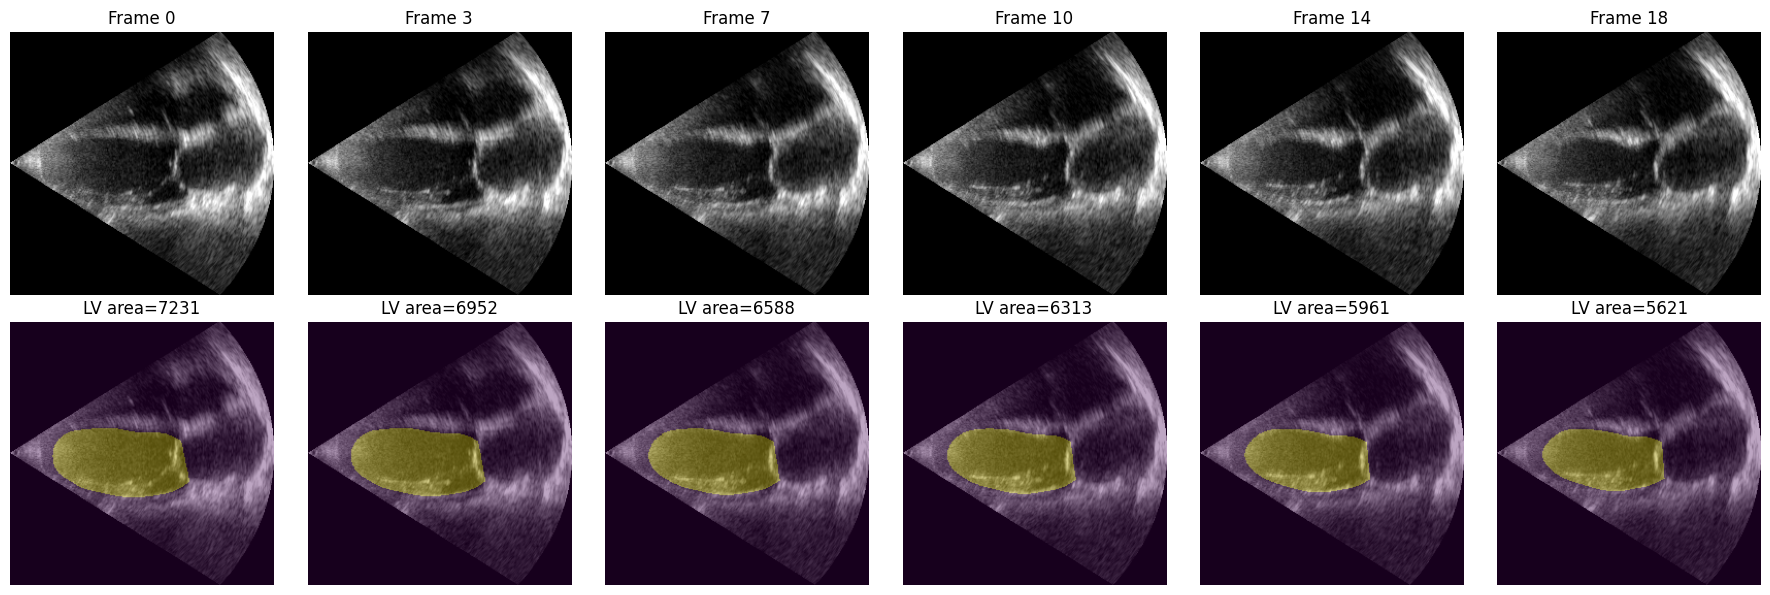

In [6]:
# ================================================================
# TEMPORAL SEQUENCE VISUALIZATION
# ================================================================

sample = load_camus_4ch_sequence(
    train_patients[0]
)

frames = sample["images"]
masks  = sample["masks"]

T = len(frames)

indices = np.linspace(
    0,
    T - 1,
    6
).astype(int)

print("Patient:", sample["patient_id"])
print("Frames:", T)

plt.figure(figsize=(18, 6))

for j, idx in enumerate(indices):

    plt.subplot(2, 6, j + 1)

    plt.imshow(
        frames[idx],
        cmap="gray"
    )

    plt.title(f"Frame {idx}")
    plt.axis("off")

    plt.subplot(2, 6, j + 7)

    plt.imshow(
        frames[idx],
        cmap="gray"
    )

    plt.imshow(
        masks[idx],
        alpha=0.35
    )

    plt.title(
        f"LV area={masks[idx].sum()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

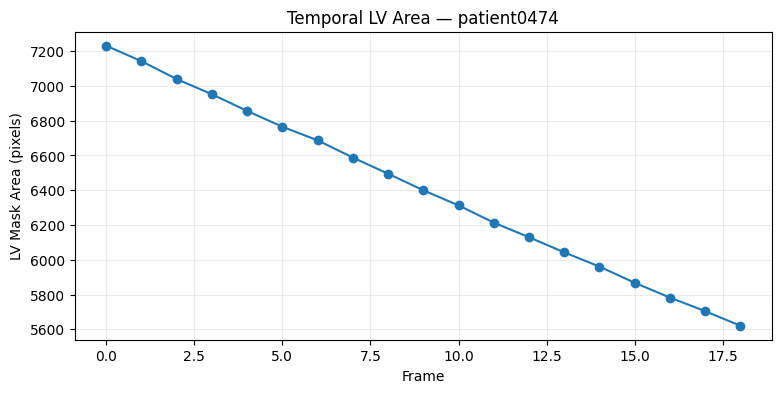

Maximum LV area: 7231
Minimum LV area: 5621
Area change: 1610
Relative contraction: 0.22265246853823814


In [7]:
# ================================================================
# CARDIAC MOTION / LV AREA CURVE
# ================================================================

areas = masks.sum(axis=(1,2))

plt.figure(figsize=(9, 4))

plt.plot(
    np.arange(T),
    areas,
    marker="o"
)

plt.xlabel("Frame")
plt.ylabel("LV Mask Area (pixels)")
plt.title(
    f"Temporal LV Area — {sample['patient_id']}"
)

plt.grid(alpha=0.25)
plt.show()

print(
    "Maximum LV area:",
    areas.max()
)

print(
    "Minimum LV area:",
    areas.min()
)

print(
    "Area change:",
    areas.max() - areas.min()
)

print(
    "Relative contraction:",
    (areas.max() - areas.min()) /
    areas.max()
)

In [8]:
# ============================================================
# CARDIOSAM-MEM — PHASE 3
# VIDEO DATASET + TEMPORAL SAMPLING
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import random

SEQ_LEN = 8
BATCH_SIZE = 2
NUM_WORKERS = 2

class CAMUSVideoDataset(Dataset):
    def __init__(
        self,
        patient_list,
        seq_len=8,
        training=True
    ):
        self.patient_list = patient_list
        self.seq_len = seq_len
        self.training = training

    def __len__(self):
        return len(self.patient_list)

    def __getitem__(self, index):

        data = load_camus_4ch_sequence(
            self.patient_list[index]
        )

        images = data["images"]
        masks = data["masks"]

        T = len(images)

        # ---------------------------------------------
        # Consecutive temporal window
        # ---------------------------------------------
        if T >= self.seq_len:

            if self.training:
                start = random.randint(
                    0,
                    T - self.seq_len
                )
            else:
                start = max(
                    0,
                    (T - self.seq_len) // 2
                )

            images = images[
                start:start+self.seq_len
            ]

            masks = masks[
                start:start+self.seq_len
            ]

        else:

            # Padding for unusually short sequence
            pad = self.seq_len - T

            images = np.concatenate([
                images,
                np.repeat(
                    images[-1:],
                    pad,
                    axis=0
                )
            ])

            masks = np.concatenate([
                masks,
                np.repeat(
                    masks[-1:],
                    pad,
                    axis=0
                )
            ])

        # ---------------------------------------------
        # Safe ultrasound augmentation
        # ---------------------------------------------
        if self.training:

            # Horizontal flip applied to whole video
            if random.random() < 0.5:
                images = images[:, :, ::-1].copy()
                masks = masks[:, :, ::-1].copy()

            # Mild brightness/gamma perturbation
            gamma = random.uniform(0.9, 1.1)
            images = np.power(
                np.clip(images, 0, 1),
                gamma
            )

            # Mild Gaussian noise
            if random.random() < 0.30:
                noise = np.random.normal(
                    0,
                    0.015,
                    images.shape
                )
                images = np.clip(
                    images + noise,
                    0,
                    1
                )

        # [T,H,W] -> [T,3,H,W]
        images = torch.from_numpy(
            images.astype(np.float32)
        ).unsqueeze(1)

        images = images.repeat(
            1, 3, 1, 1
        )

        masks = torch.from_numpy(
            masks.astype(np.float32)
        ).unsqueeze(1)

        return {
            "images": images,
            "masks": masks,
            "patient_id": data["patient_id"]
        }


train_dataset = CAMUSVideoDataset(
    train_patients,
    SEQ_LEN,
    True
)

val_dataset = CAMUSVideoDataset(
    val_patients,
    SEQ_LEN,
    False
)

test_dataset = CAMUSVideoDataset(
    test_patients,
    SEQ_LEN,
    False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

batch = next(iter(train_loader))

print("Images:", batch["images"].shape)
print("Masks :", batch["masks"].shape)
print("Patients:", batch["patient_id"])
print("Image range:",
      batch["images"].min().item(),
      batch["images"].max().item())
print("Mask labels:",
      torch.unique(batch["masks"]))

Images: torch.Size([2, 8, 3, 256, 256])
Masks : torch.Size([2, 8, 1, 256, 256])
Patients: ['patient0372', 'patient0476']
Image range: 0.0 1.0
Mask labels: tensor([0., 1.])


In [9]:
!pip install -q git+https://github.com/facebookresearch/sam2.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 454.1 kB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 8.0 MB/s eta 0:00:00


In [10]:
!wget -q \
https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt \
-O /kaggle/working/sam2.1_hiera_tiny.pt

print("Checkpoint downloaded.")

Checkpoint downloaded.


In [11]:
import torch.nn as nn
import torch.nn.functional as F

EPS = 1e-6

def prediction_uncertainty(logits):

    p = torch.sigmoid(logits)

    entropy = -(
        p * torch.log(p + EPS)
        +
        (1-p) * torch.log(1-p + EPS)
    )

    # normalize binary entropy
    entropy = entropy / np.log(2)

    return entropy

In [12]:
# ============================================================
# DEVICE SETUP
# ============================================================

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: Tesla T4


In [13]:
# ============================================================
# SOFT CENTROID + AREA — FIXED
# ============================================================

def soft_centroid(prob):

    B, C, H, W = prob.shape

    yy, xx = torch.meshgrid(
        torch.linspace(
            0, 1, H,
            device=prob.device,
            dtype=prob.dtype
        ),
        torch.linspace(
            0, 1, W,
            device=prob.device,
            dtype=prob.dtype
        ),
        indexing="ij"
    )

    # Remove channel dimension
    # [B,1,H,W] -> [B,H,W]
    p = prob[:, 0]

    mass = (
        p.sum(dim=(1, 2))
        + EPS
    )

    cx = (
        (p * xx).sum(dim=(1, 2))
        / mass
    )

    cy = (
        (p * yy).sum(dim=(1, 2))
        / mass
    )

    # Output: [B,2]
    return torch.stack(
        [cx, cy],
        dim=-1
    )


def soft_area(prob):

    return prob.mean(
        dim=(1, 2, 3)
    )

In [14]:
dummy = torch.rand(
    2, 1, 256, 256,
    device=DEVICE
)

print(
    "Centroid shape:",
    soft_centroid(dummy).shape
)

print(
    "Area shape:",
    soft_area(dummy).shape
)

Centroid shape: torch.Size([2, 2])
Area shape: torch.Size([2])


In [15]:
# ============================================================
# TEMPORAL ANATOMY LOSS — SECOND-ORDER JITTER CONTROL
# Preserves normal cardiac contraction/expansion while penalizing
# abrupt acceleration (temporal jitter) in area and centroid.
# ============================================================

def temporal_anatomy_loss(current_prob, previous_prob, previous2_prob=None):
    if previous_prob is None:
        return torch.tensor(0.0, device=current_prob.device, dtype=current_prob.dtype)

    area_now = soft_area(current_prob)
    area_prev = soft_area(previous_prob)
    center_now = soft_centroid(current_prob)
    center_prev = soft_centroid(previous_prob)

    # For the first propagated pair there is no acceleration estimate yet.
    if previous2_prob is None:
        # Small motion regularizer only; normal contraction is not forced to zero.
        center_step = torch.norm(center_now - center_prev, dim=-1).mean()
        return 0.25 * center_step

    area_prev2 = soft_area(previous2_prob)
    center_prev2 = soft_centroid(previous2_prob)

    # Second-order finite differences = jitter/acceleration, not motion itself.
    area_acc = torch.abs(
        area_now - 2.0 * area_prev + area_prev2
    ) / (area_prev.detach() + EPS)

    center_acc = torch.norm(
        center_now - 2.0 * center_prev + center_prev2,
        dim=-1
    )

    return area_acc.mean() + center_acc.mean()


In [16]:
# ============================================================
# BOUNDARY + DIFFERENTIABLE TOPOLOGY CONSTRAINT
# LV cavity should form one simply connected region (Euler ~= 1).
# ============================================================

def soft_erode(x):
    return -F.max_pool2d(-x, kernel_size=3, stride=1, padding=1)


def soft_boundary(x):
    eroded = soft_erode(x)
    return torch.clamp(x - eroded, min=0)


def boundary_loss(pred_prob, target):
    pred_edge = soft_boundary(pred_prob)
    gt_edge = soft_boundary(target)
    intersection = (pred_edge * gt_edge).sum(dim=(1, 2, 3))
    denominator = pred_edge.sum(dim=(1, 2, 3)) + gt_edge.sum(dim=(1, 2, 3))
    score = (2 * intersection + EPS) / (denominator + EPS)
    return 1 - score.mean()


def _soft_or(values, dim=0):
    """Differentiable OR for probabilities in [0,1]."""
    return 1.0 - torch.prod(1.0 - values.clamp(0, 1), dim=dim)


def soft_euler_characteristic(prob):
    """
    Differentiable cubical-complex Euler characteristic of a soft foreground.
    For a binary simply connected LV cavity, chi = components - holes = 1.
    Returns one value per sample.
    """
    p = prob[:, 0].clamp(0, 1)  # [B,H,W]
    B, H, W = p.shape

    # Faces: foreground pixels.
    F_faces = p.sum(dim=(1, 2))

    # Horizontal grid edges: occupied if either pixel touching the edge is FG.
    # Boundary edges have one adjacent pixel.
    top = p[:, 0, :].sum(dim=1)
    bottom = p[:, -1, :].sum(dim=1)
    if H > 1:
        h_internal = (1.0 - (1.0 - p[:, :-1, :]) * (1.0 - p[:, 1:, :])).sum(dim=(1, 2))
    else:
        h_internal = torch.zeros(B, device=p.device, dtype=p.dtype)

    # Vertical grid edges.
    left = p[:, :, 0].sum(dim=1)
    right = p[:, :, -1].sum(dim=1)
    if W > 1:
        v_internal = (1.0 - (1.0 - p[:, :, :-1]) * (1.0 - p[:, :, 1:])).sum(dim=(1, 2))
    else:
        v_internal = torch.zeros(B, device=p.device, dtype=p.dtype)

    E_edges = top + bottom + left + right + h_internal + v_internal

    # Grid vertices: OR of up to four incident pixels. Padding with zero FG
    # lets one expression handle interior and boundary vertices.
    q = F.pad(p, (1, 1, 1, 1), value=0.0)
    a = q[:, :-1, :-1]
    b = q[:, :-1, 1:]
    c = q[:, 1:, :-1]
    d = q[:, 1:, 1:]
    V_vertices = (1.0 - (1-a)*(1-b)*(1-c)*(1-d)).sum(dim=(1, 2))

    return V_vertices - E_edges + F_faces


def topology_loss(pred_prob, target):
    """Match predicted Euler topology to GT and LV prior chi=1."""
    chi_pred = soft_euler_characteristic(pred_prob)
    with torch.no_grad():
        chi_gt = soft_euler_characteristic(target.float())

    match_gt = torch.abs(chi_pred - chi_gt)
    lv_prior = torch.abs(chi_pred - 1.0)
    # Smooth bounded penalty so scale stays compatible with existing weights.
    return (torch.tanh(match_gt) + 0.5 * torch.tanh(lv_prior)).mean()


def anatomical_topology_loss(pred_prob, target):
    # Keep the SAME overall 0.15 loss weight later; split internally.
    return 0.5 * boundary_loss(pred_prob, target) + 0.5 * topology_loss(pred_prob, target)


In [17]:
def dice_loss(
    logits,
    target
):

    probability = torch.sigmoid(
        logits
    )

    intersection = (
        probability*target
    ).sum(dim=(1,2,3))

    denominator = (
        probability.sum(dim=(1,2,3))
        +
        target.sum(dim=(1,2,3))
    )

    dice = (
        2*intersection + EPS
    ) / (
        denominator + EPS
    )

    return 1-dice.mean()


def segmentation_loss(
    logits,
    target
):

    dice = dice_loss(
        logits,
        target
    )

    bce = F.binary_cross_entropy_with_logits(
        logits,
        target
    )

    return 0.7*dice + 0.3*bce

In [18]:
def cardio_reliability(
    current_logits,
    previous_prob=None
):

    prob = torch.sigmoid(
        current_logits
    )

    # -----------------------------------------
    # Confidence reliability
    # -----------------------------------------
    uncertainty = prediction_uncertainty(
        current_logits
    )

    confidence = (
        1-uncertainty
    ).mean(dim=(1,2,3))

    if previous_prob is None:

        temporal = torch.ones_like(
            confidence
        )

        anatomy = torch.ones_like(
            confidence
        )

    else:

        # -----------------------------------------
        # Anatomical area plausibility
        # -----------------------------------------

        area_now = soft_area(prob)
        area_prev = soft_area(
            previous_prob
        )

        relative_area_change = (
            torch.abs(
                area_now-area_prev
            )
            /
            (area_prev+EPS)
        )

        anatomy = torch.exp(
            -2.0*relative_area_change
        )

        # -----------------------------------------
        # Temporal centroid consistency
        # -----------------------------------------

        center_now = soft_centroid(
            prob
        )

        center_prev = soft_centroid(
            previous_prob
        )

        displacement = torch.norm(
            center_now-center_prev,
            dim=-1
        )

        temporal = torch.exp(
            -5.0*displacement
        )

    reliability = (
        confidence *
        anatomy *
        temporal
    )

    return torch.clamp(
        reliability,
        0,
        1
    )

In [19]:
# ============================================================
# LOAD SAM2.1 HIERA-TINY
# ============================================================

import os
import torch

from sam2.build_sam import build_sam2

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

SAM2_CHECKPOINT = "/kaggle/working/sam2.1_hiera_tiny.pt"

# IMPORTANT:
# build_sam2 expects Hydra config name, not a local absolute path
SAM2_CONFIG = "configs/sam2.1/sam2.1_hiera_t.yaml"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Checkpoint exists:", os.path.exists(SAM2_CHECKPOINT))
print("Config:", SAM2_CONFIG)

assert os.path.exists(SAM2_CHECKPOINT), (
    f"Checkpoint not found: {SAM2_CHECKPOINT}"
)

# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

sam2 = build_sam2(
    SAM2_CONFIG,
    SAM2_CHECKPOINT,
    device=DEVICE
)

print("\nSAM2 successfully loaded!")
print("Model type:", type(sam2))

# ------------------------------------------------------------
# MEMORY ENCODER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY ENCODER")
print("=" * 70)

print(sam2.memory_encoder)

# ------------------------------------------------------------
# MEMORY ATTENTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY ATTENTION")
print("=" * 70)

print(sam2.memory_attention)

# ------------------------------------------------------------
# IMAGE ENCODER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE ENCODER")
print("=" * 70)

print(type(sam2.image_encoder))

# ------------------------------------------------------------
# MASK DECODER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MASK DECODER")
print("=" * 70)

if hasattr(sam2, "sam_mask_decoder"):
    print(sam2.sam_mask_decoder)
else:
    print("sam_mask_decoder attribute not found")

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in sam2.parameters()
)

trainable_params = sum(
    p.numel()
    for p in sam2.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("PARAMETERS")
print("=" * 70)

print(
    f"Total parameters: "
    f"{total_params / 1e6:.2f} M"
)

print(
    f"Currently trainable: "
    f"{trainable_params / 1e6:.2f} M"
)

# ------------------------------------------------------------
# FIND MEMORY-RELATED MODULES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY / DECODER MODULE NAMES")
print("=" * 70)

for name, module in sam2.named_modules():

    if (
        "memory" in name.lower()
        or "mask_decoder" in name.lower()
    ):

        print(
            f"{name:60s} -> "
            f"{module.__class__.__name__}"
        )

Device: cuda
Checkpoint exists: True
Config: configs/sam2.1/sam2.1_hiera_t.yaml

SAM2 successfully loaded!
Model type: <class 'sam2.modeling.sam2_base.SAM2Base'>

MEMORY ENCODER
MemoryEncoder(
  (mask_downsampler): MaskDownSampler(
    (encoder): Sequential(
      (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): LayerNorm2d()
      (2): GELU(approximate='none')
      (3): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): LayerNorm2d()
      (5): GELU(approximate='none')
      (6): Conv2d(16, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (7): LayerNorm2d()
      (8): GELU(approximate='none')
      (9): Conv2d(64, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (10): LayerNorm2d()
      (11): GELU(approximate='none')
      (12): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (pix_feat_proj): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
  (fuser): Fuser(
    (proj): Identity()
   

In [20]:
# ============================================================
# PHASE 9 — FREEZE / UNFREEZE CARDIOSAM-MEM
# ============================================================

# Freeze everything
for p in sam2.parameters():
    p.requires_grad = False

# Train SAM2 memory encoder
for p in sam2.memory_encoder.parameters():
    p.requires_grad = True

# Train SAM2 memory attention
for p in sam2.memory_attention.parameters():
    p.requires_grad = True

# Train mask decoder
for p in sam2.sam_mask_decoder.parameters():
    p.requires_grad = True


total = sum(p.numel() for p in sam2.parameters())
trainable = sum(
    p.numel()
    for p in sam2.parameters()
    if p.requires_grad
)

print(f"Total:     {total/1e6:.2f} M")
print(f"Trainable: {trainable/1e6:.2f} M")
print(
    f"Trainable percentage: "
    f"{100*trainable/total:.2f}%"
)

sam2.train()

Total:     38.96 M
Trainable: 11.52 M
Trainable percentage: 29.57%


SAM2Base(
  (image_encoder): ImageEncoder(
    (trunk): Hiera(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 96, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
      )
      (blocks): ModuleList(
        (0): MultiScaleBlock(
          (norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (attn): MultiScaleAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (proj): Linear(in_features=96, out_features=96, bias=True)
          )
          (drop_path): Identity()
          (norm2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): MLP(
            (layers): ModuleList(
              (0): Linear(in_features=96, out_features=384, bias=True)
              (1): Linear(in_features=384, out_features=96, bias=True)
            )
            (act): GELU(approximate='none')
          )
        )
        (1): MultiScaleBlock(
          (norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
      

In [21]:
# ============================================================
# LEARNABLE CARDIAC RELIABILITY GATE
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class CardiacReliabilityGate(nn.Module):
    """
    Learns memory reliability from:
       1. prediction confidence
       2. anatomical plausibility
       3. temporal consistency
    """

    def __init__(self):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(3, 16),
            nn.GELU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(
        self,
        confidence,
        anatomy,
        temporal
    ):

        x = torch.stack(
            [confidence, anatomy, temporal],
            dim=-1
        )

        return self.gate(x).squeeze(-1)


reliability_gate = CardiacReliabilityGate().to(DEVICE)

print(reliability_gate)

print(
    "Gate parameters:",
    sum(
        p.numel()
        for p in reliability_gate.parameters()
    )
)

CardiacReliabilityGate(
  (gate): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=16, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
Gate parameters: 81


In [22]:
# ============================================================
# RELIABILITY COMPONENTS — CONFIDENCE + ANATOMY + TEMPORAL
# ============================================================

EPS = 1e-6


def reliability_components(logits, previous_prob=None):
    prob = torch.sigmoid(logits)

    # 1) Prediction confidence from normalized binary entropy.
    entropy = -(prob * torch.log(prob + EPS) + (1-prob) * torch.log(1-prob + EPS))
    entropy = entropy / np.log(2)
    confidence = (1 - entropy).mean(dim=(1, 2, 3))

    if previous_prob is None:
        anatomy = torch.ones_like(confidence)
        temporal = torch.ones_like(confidence)
        return confidence, anatomy, temporal

    # 2) Anatomical plausibility.
    # Allow physiologic frame-to-frame area change up to 15% without penalty.
    area_now = soft_area(prob)
    area_previous = soft_area(previous_prob)
    relative_change = torch.abs(area_now - area_previous) / (area_previous + EPS)
    excess_change = torch.relu(relative_change - 0.15)
    anatomy = torch.exp(-2.0 * excess_change)

    # 3) Temporal consistency from normalized centroid displacement.
    centroid_now = soft_centroid(prob)
    centroid_previous = soft_centroid(previous_prob)
    displacement = torch.norm(centroid_now - centroid_previous, dim=-1)
    temporal = torch.exp(-5.0 * displacement)

    return confidence, anatomy, temporal


In [23]:
def compute_reliability(
    logits,
    previous_prob=None
):

    confidence, anatomy, temporal = (
        reliability_components(
            logits,
            previous_prob
        )
    )

    reliability = reliability_gate(
        confidence,
        anatomy,
        temporal
    )

    return (
        reliability,
        confidence,
        anatomy,
        temporal
    )

In [24]:
# ============================================================
# CARDIOSAM-MEM LOSS — FULL NOVELTY OBJECTIVE
# Existing global weights are preserved: 0.15 anatomy/topology + 0.10 temporal.
# ============================================================

def cardio_loss(logits, target, previous_prob=None, previous2_prob=None):
    prob = torch.sigmoid(logits)

    # Standard segmentation.
    seg = segmentation_loss(logits, target)

    # Boundary + genuine differentiable topology constraint.
    topo = anatomical_topology_loss(prob, target)

    # Second-order temporal anatomy consistency.
    temporal = temporal_anatomy_loss(
        prob,
        previous_prob,
        previous2_prob
    )

    total = seg + 0.15 * topo + 0.10 * temporal

    return {
        "total": total,
        "seg": seg,
        "topology": topo,
        "temporal": temporal
    }


In [25]:
# ============================================================
# SAM2 IMAGE ENCODER SANITY TEST
# ============================================================

sam2.eval()

batch = next(iter(train_loader))

images = batch["images"].to(
    DEVICE,
    non_blocking=True
)

masks = batch["masks"].to(
    DEVICE,
    non_blocking=True
)

print("Input video:", images.shape)
print("GT video:", masks.shape)

# First frame
frame = images[:, 0]

print("Frame:", frame.shape)

with torch.no_grad():

    backbone_out = sam2.forward_image(
        frame
    )

print("\nBackbone output keys:")

if isinstance(backbone_out, dict):

    for key, value in backbone_out.items():

        if torch.is_tensor(value):

            print(
                key,
                tuple(value.shape)
            )

        elif isinstance(value, list):

            print(
                key,
                [
                    tuple(x.shape)
                    if torch.is_tensor(x)
                    else type(x)
                    for x in value
                ]
            )

        else:

            print(
                key,
                type(value)
            )

Input video: torch.Size([2, 8, 3, 256, 256])
GT video: torch.Size([2, 8, 1, 256, 256])
Frame: torch.Size([2, 3, 256, 256])

Backbone output keys:
vision_features (2, 256, 16, 16)
vision_pos_enc [(2, 256, 64, 64), (2, 256, 32, 32), (2, 256, 16, 16)]
backbone_fpn [(2, 32, 64, 64), (2, 64, 32, 32), (2, 256, 16, 16)]


In [26]:
import inspect

print(inspect.signature(sam2._track_step))

(frame_idx, is_init_cond_frame, current_vision_feats, current_vision_pos_embeds, feat_sizes, point_inputs, mask_inputs, output_dict, num_frames, track_in_reverse, prev_sam_mask_logits)


In [27]:
# ============================================================
# SAM2 FEATURE PREPARATION — FIXED FOR NATIVE SAM2 SIZE
# ============================================================

def prepare_sam2_features(model, frame):

    sam_size = model.image_size

    if isinstance(sam_size, (tuple, list)):
        target_size = tuple(sam_size)
    else:
        target_size = (sam_size, sam_size)

    # 256x256 dataset frame -> native SAM2 resolution
    if frame.shape[-2:] != target_size:

        frame = F.interpolate(
            frame,
            size=target_size,
            mode="bilinear",
            align_corners=False
        )

    backbone_out = model.forward_image(frame)

    _, vision_feats, vision_pos, feat_sizes = (
        model._prepare_backbone_features(
            backbone_out
        )
    )

    return (
        vision_feats,
        vision_pos,
        feat_sizes
    )

In [28]:
batch = next(iter(train_loader))

test_frame = batch["images"][:, 0].to(DEVICE)

with torch.no_grad():

    vf, vp, fs = prepare_sam2_features(
        sam2,
        test_frame
    )

print("SAM2 image size:", sam2.image_size)
print("Original frame:", test_frame.shape)
print("Feature sizes:", fs)
print("Final feature size:", fs[-1])
print(
    "Expected embedding size:",
    sam2.sam_image_embedding_size
)

SAM2 image size: 1024
Original frame: torch.Size([2, 3, 256, 256])
Feature sizes: [(256, 256), (128, 128), (64, 64)]
Final feature size: (64, 64)
Expected embedding size: 64


In [29]:
# ============================================================
# METRICS
# ============================================================

def batch_dice_from_logits(logits, target):

    if logits.shape[-2:] != target.shape[-2:]:
        logits = F.interpolate(
            logits,
            size=target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

    pred = (
        torch.sigmoid(logits) > 0.5
    ).float()

    intersection = (
        pred * target
    ).sum(dim=(1,2,3))

    denominator = (
        pred.sum(dim=(1,2,3))
        +
        target.sum(dim=(1,2,3))
    )

    return (
        (2*intersection + 1e-6)
        /
        (denominator + 1e-6)
    ).mean()


def batch_iou_from_logits(logits, target):

    if logits.shape[-2:] != target.shape[-2:]:
        logits = F.interpolate(
            logits,
            size=target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

    pred = (
        torch.sigmoid(logits) > 0.5
    ).float()

    intersection = (
        pred * target
    ).sum(dim=(1,2,3))

    union = (
        pred + target -
        pred*target
    ).sum(dim=(1,2,3))

    return (
        (intersection + 1e-6)
        /
        (union + 1e-6)
    ).mean()

In [30]:
# ============================================================
# CARDIOSAM-MEM VIDEO FORWARD — FULL RELIABILITY-GUIDED MEMORY
# Reliability now directly controls what enters SAM2 memory.
# ============================================================

def _gate_sam2_memory(current_out, reliability, previous_memory=None):
    """
    Soft memory admission/blending.
    High reliability -> write current memory strongly.
    Low reliability  -> retain more of previous reliable memory.
    This changes subsequent SAM2 predictions, so the reliability gate is
    trained end-to-end through future-frame segmentation loss.
    """
    if current_out.get("maskmem_features", None) is None:
        return current_out

    new_mem = current_out["maskmem_features"]
    r = reliability.view(-1, 1, 1, 1).to(dtype=new_mem.dtype)

    if previous_memory is not None and previous_memory.shape == new_mem.shape:
        # Detach previous state to avoid an unnecessarily long recurrent graph.
        gated_mem = r * new_mem + (1.0 - r) * previous_memory.detach()
    else:
        # Fallback soft admission when no compatible previous memory exists.
        gated_mem = r * new_mem

    # Do not mutate SAM2's returned dictionary in-place unexpectedly.
    out = dict(current_out)
    out["maskmem_features"] = gated_mem
    out["cardiac_reliability"] = reliability
    return out


def forward_video(model, images, masks, training=True):
    B, T, C, H, W = images.shape

    output_dict = {
        "cond_frame_outputs": {},
        "non_cond_frame_outputs": {}
    }

    frame_outputs = []
    reliability_values = []
    previous_prob = None
    previous_memory = None

    for t in range(T):
        frame = images[:, t]

        vision_feats, vision_pos, feat_sizes = prepare_sam2_features(model, frame)

        if t == 0:
            mask_inputs = F.interpolate(
                masks[:, t].float(),
                size=(model.image_size, model.image_size),
                mode="nearest"
            )
            is_init = True
        else:
            mask_inputs = None
            is_init = False

        current_out = model.track_step(
            frame_idx=t,
            is_init_cond_frame=is_init,
            current_vision_feats=vision_feats,
            current_vision_pos_embeds=vision_pos,
            feat_sizes=feat_sizes,
            point_inputs=None,
            mask_inputs=mask_inputs,
            output_dict=output_dict,
            num_frames=T,
            track_in_reverse=False,
            run_mem_encoder=True,
            prev_sam_mask_logits=None
        )

        logits = current_out["pred_masks"]
        logits_up = F.interpolate(
            logits,
            size=(H, W),
            mode="bilinear",
            align_corners=False
        )

        reliability, confidence, anatomy, temporal = compute_reliability(
            logits_up,
            previous_prob
        )
        reliability_values.append(reliability)

        # First GT-conditioned memory remains intact. Reliability gating begins
        # on propagated frames, where memory contamination can occur.
        if t == 0:
            gated_out = current_out
        else:
            gated_out = _gate_sam2_memory(
                current_out,
                reliability,
                previous_memory
            )

        if t == 0:
            output_dict["cond_frame_outputs"][t] = gated_out
        else:
            output_dict["non_cond_frame_outputs"][t] = gated_out

        if gated_out.get("maskmem_features", None) is not None:
            previous_memory = gated_out["maskmem_features"]

        frame_outputs.append(logits_up)
        previous_prob = torch.sigmoid(logits_up)

    predictions = torch.stack(frame_outputs, dim=1)
    reliability_values = torch.stack(reliability_values, dim=1)
    return predictions, reliability_values


In [31]:
# ============================================================
# VIDEO LOSS — SECOND-ORDER TEMPORAL CONTEXT
# ============================================================

def compute_video_loss(predictions, targets):
    B, T, _, H, W = predictions.shape

    total_loss = 0.0
    seg_total = 0.0
    topo_total = 0.0
    temporal_total = 0.0

    previous_prob = None
    previous2_prob = None

    # Skip GT conditioning frame t=0.
    for t in range(1, T):
        logits = predictions[:, t]
        gt = targets[:, t]

        losses = cardio_loss(
            logits,
            gt,
            previous_prob,
            previous2_prob
        )

        total_loss += losses["total"]
        seg_total += losses["seg"]
        topo_total += losses["topology"]
        temporal_total += losses["temporal"]

        current_prob = torch.sigmoid(logits)
        previous2_prob = previous_prob
        previous_prob = current_prob

    n = T - 1
    return {
        "total": total_loss / n,
        "seg": seg_total / n,
        "topology": topo_total / n,
        "temporal": temporal_total / n
    }


In [32]:
# ============================================================
# OPTIMIZER
# ============================================================

trainable_parameters = (
    [
        p for p in sam2.parameters()
        if p.requires_grad
    ]
    +
    list(reliability_gate.parameters())
)

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=1e-5,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print(
    "Optimized parameters:",
    sum(
        p.numel()
        for p in trainable_parameters
    ) / 1e6,
    "M"
)

Optimized parameters: 11.522102 M


In [33]:
# ============================================================
# ONE-BATCH FORWARD TEST
# ============================================================

sam2.train()
reliability_gate.train()

batch = next(iter(train_loader))

images = batch["images"].to(
    DEVICE,
    non_blocking=True
)

masks = batch["masks"].to(
    DEVICE,
    non_blocking=True
)

print("Images:", images.shape)
print("Masks :", masks.shape)

optimizer.zero_grad(
    set_to_none=True
)

with torch.amp.autocast(
    "cuda",
    enabled=torch.cuda.is_available()
):

    predictions, reliability = (
        forward_video(
            sam2,
            images,
            masks,
            training=True
        )
    )

    losses = compute_video_loss(
        predictions,
        masks
    )

print(
    "Predictions:",
    predictions.shape
)

print(
    "Reliability:",
    reliability.shape
)

print(
    "Reliability mean:",
    reliability.mean().item()
)

print(
    "Total loss:",
    losses["total"].item()
)

print(
    "Seg loss:",
    losses["seg"].item()
)

print(
    "Topology loss:",
    losses["topology"].item()
)

print(
    "Temporal loss:",
    losses["temporal"].item()
)

dice = batch_dice_from_logits(
    predictions[:, 1:].reshape(
        -1, 1, 256, 256
    ),
    masks[:, 1:].reshape(
        -1, 1, 256, 256
    )
)

print(
    "Initial Dice:",
    dice.item()
)

# backward sanity test
scaler.scale(
    losses["total"]
).backward()

scaler.unscale_(
    optimizer
)

torch.nn.utils.clip_grad_norm_(
    trainable_parameters,
    1.0
)

scaler.step(
    optimizer
)

scaler.update()

print("\n✓ Forward/backward successful")

Images: torch.Size([2, 8, 3, 256, 256])
Masks : torch.Size([2, 8, 1, 256, 256])
Predictions: torch.Size([2, 8, 1, 256, 256])
Reliability: torch.Size([2, 8])
Reliability mean: 0.505859375
Total loss: 0.24322935938835144
Seg loss: 0.06593829393386841
Topology loss: 1.1611257791519165
Temporal loss: 0.031221851706504822
Initial Dice: 0.9518283605575562

✓ Forward/backward successful


In [34]:
# ============================================================
# TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS = 10

print("Training configuration")
print("Epochs       :", NUM_EPOCHS)
print("Device       :", DEVICE)
print("Trainable M  :", sum(
    p.numel() for p in trainable_parameters
) / 1e6)

Training configuration
Epochs       : 10
Device       : cuda
Trainable M  : 11.522102


In [35]:
# ============================================================
# SEGMENTATION METRICS
# ============================================================

@torch.no_grad()
def segmentation_metrics(
    logits,
    targets,
    threshold=0.5,
    eps=1e-7
):

    probs = torch.sigmoid(logits)

    preds = (
        probs > threshold
    ).float()

    targets = (
        targets > 0.5
    ).float()

    dims = (1, 2, 3)

    intersection = (
        preds * targets
    ).sum(dim=dims)

    pred_sum = preds.sum(dim=dims)
    target_sum = targets.sum(dim=dims)

    dice = (
        2.0 * intersection + eps
    ) / (
        pred_sum +
        target_sum +
        eps
    )

    union = (
        pred_sum +
        target_sum -
        intersection
    )

    iou = (
        intersection + eps
    ) / (
        union + eps
    )

    return (
        dice.mean().item(),
        iou.mean().item()
    )

In [36]:
# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    reliability_gate,
    loader,
    optimizer,
    scaler
):

    model.train()
    reliability_gate.train()

    running_total = 0.0
    running_seg = 0.0
    running_topology = 0.0
    running_temporal = 0.0

    running_dice = 0.0
    running_iou = 0.0
    running_reliability = 0.0

    num_batches = 0

    for batch_idx, batch in enumerate(loader):

        images = batch["images"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["masks"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            predictions, reliability = (
                forward_video(
                    model,
                    images,
                    masks,
                    training=True
                )
            )

            losses = compute_video_loss(
                predictions,
                masks
            )

        scaler.scale(
            losses["total"]
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=1.0
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        # ----------------------------------------
        # Metrics: exclude conditioning frame t=0
        # ----------------------------------------

        metric_logits = (
            predictions[:, 1:]
            .reshape(
                -1,
                1,
                predictions.shape[-2],
                predictions.shape[-1]
            )
        )

        metric_masks = (
            masks[:, 1:]
            .reshape(
                -1,
                1,
                masks.shape[-2],
                masks.shape[-1]
            )
        )

        dice, iou = segmentation_metrics(
            metric_logits.detach(),
            metric_masks
        )

        running_total += (
            losses["total"].detach().item()
        )

        running_seg += (
            losses["seg"].detach().item()
        )

        running_topology += (
            losses["topology"].detach().item()
        )

        running_temporal += (
            losses["temporal"].detach().item()
        )

        running_dice += dice
        running_iou += iou

        running_reliability += (
            reliability.detach()
            .mean()
            .item()
        )

        num_batches += 1

        if (
            batch_idx == 0 or
            (batch_idx + 1) % 20 == 0
        ):

            print(
                f"  Batch "
                f"{batch_idx + 1:03d}/"
                f"{len(loader):03d} | "
                f"Loss {losses['total'].item():.4f} | "
                f"Dice {dice:.4f} | "
                f"IoU {iou:.4f}"
            )

    return {

        "loss":
            running_total / num_batches,

        "seg":
            running_seg / num_batches,

        "topology":
            running_topology / num_batches,

        "temporal":
            running_temporal / num_batches,

        "dice":
            running_dice / num_batches,

        "iou":
            running_iou / num_batches,

        "reliability":
            running_reliability / num_batches
    }

In [37]:
# ============================================================
# VALIDATION
# ============================================================

@torch.no_grad()
def validate_one_epoch(
    model,
    reliability_gate,
    loader
):

    model.eval()
    reliability_gate.eval()

    running_total = 0.0
    running_seg = 0.0
    running_topology = 0.0
    running_temporal = 0.0

    running_dice = 0.0
    running_iou = 0.0
    running_reliability = 0.0

    num_batches = 0

    for batch in loader:

        images = batch["images"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["masks"].to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            predictions, reliability = (
                forward_video(
                    model,
                    images,
                    masks,
                    training=False
                )
            )

            losses = compute_video_loss(
                predictions,
                masks
            )

        # Exclude first GT-conditioned frame
        metric_logits = (
            predictions[:, 1:]
            .reshape(
                -1,
                1,
                predictions.shape[-2],
                predictions.shape[-1]
            )
        )

        metric_masks = (
            masks[:, 1:]
            .reshape(
                -1,
                1,
                masks.shape[-2],
                masks.shape[-1]
            )
        )

        dice, iou = segmentation_metrics(
            metric_logits,
            metric_masks
        )

        running_total += (
            losses["total"].item()
        )

        running_seg += (
            losses["seg"].item()
        )

        running_topology += (
            losses["topology"].item()
        )

        running_temporal += (
            losses["temporal"].item()
        )

        running_dice += dice
        running_iou += iou

        running_reliability += (
            reliability.mean().item()
        )

        num_batches += 1

    return {

        "loss":
            running_total / num_batches,

        "seg":
            running_seg / num_batches,

        "topology":
            running_topology / num_batches,

        "temporal":
            running_temporal / num_batches,

        "dice":
            running_dice / num_batches,

        "iou":
            running_iou / num_batches,

        "reliability":
            running_reliability / num_batches
    }

In [38]:
# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=1e-7
)

print("Scheduler ready")

Scheduler ready


In [39]:
# ============================================================
# FULL TRAINING LOOP — NO EARLY STOPPING
# ============================================================

import os
import time

BEST_PATH = (
    "/kaggle/working/"
    "cardiosam_mem_best.pth"
)

FINAL_PATH = (
    "/kaggle/working/"
    "cardiosam_mem_final.pth"
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],
    "train_reliability": [],
    "val_reliability": [],
    "lr": []
}

best_val_dice = -1.0

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    print("\n" + "=" * 70)

    print(
        f"EPOCH "
        f"{epoch + 1:02d}/"
        f"{NUM_EPOCHS:02d}"
    )

    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_stats = train_one_epoch(
        sam2,
        reliability_gate,
        train_loader,
        optimizer,
        scaler
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    val_stats = validate_one_epoch(
        sam2,
        reliability_gate,
        val_loader
    )

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------

    history["train_loss"].append(
        train_stats["loss"]
    )

    history["val_loss"].append(
        val_stats["loss"]
    )

    history["train_dice"].append(
        train_stats["dice"]
    )

    history["val_dice"].append(
        val_stats["dice"]
    )

    history["train_iou"].append(
        train_stats["iou"]
    )

    history["val_iou"].append(
        val_stats["iou"]
    )

    history[
        "train_reliability"
    ].append(
        train_stats["reliability"]
    )

    history[
        "val_reliability"
    ].append(
        val_stats["reliability"]
    )

    history["lr"].append(
        current_lr
    )

    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if val_stats["dice"] > best_val_dice:

        best_val_dice = (
            val_stats["dice"]
        )

        torch.save(
            {
                "epoch":
                    epoch + 1,

                "sam2_state_dict":
                    sam2.state_dict(),

                "reliability_gate_state_dict":
                    reliability_gate.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "history":
                    history
            },
            BEST_PATH
        )

        best_message = "  <-- BEST SAVED"

    else:

        best_message = ""

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step()

    epoch_time = (
        time.time() - start_time
    )

    # --------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------

    print("\nTRAIN")
    print(
        f"Loss        : "
        f"{train_stats['loss']:.4f}"
    )
    print(
        f"Dice        : "
        f"{train_stats['dice']:.4f}"
    )
    print(
        f"IoU         : "
        f"{train_stats['iou']:.4f}"
    )
    print(
        f"Reliability : "
        f"{train_stats['reliability']:.4f}"
    )

    print("\nVALIDATION")
    print(
        f"Loss        : "
        f"{val_stats['loss']:.4f}"
    )
    print(
        f"Dice        : "
        f"{val_stats['dice']:.4f}"
        f"{best_message}"
    )
    print(
        f"IoU         : "
        f"{val_stats['iou']:.4f}"
    )
    print(
        f"Reliability : "
        f"{val_stats['reliability']:.4f}"
    )

    print(
        f"\nLR          : "
        f"{current_lr:.2e}"
    )

    print(
        f"Epoch time  : "
        f"{epoch_time / 60:.2f} min"
    )

    print(
        f"Best Val Dice: "
        f"{best_val_dice:.4f}"
    )

# ============================================================
# SAVE FINAL EPOCH MODEL
# ============================================================

torch.save(
    {
        "epoch":
            NUM_EPOCHS,

        "sam2_state_dict":
            sam2.state_dict(),

        "reliability_gate_state_dict":
            reliability_gate.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "best_val_dice":
            best_val_dice,

        "history":
            history
    },
    FINAL_PATH
)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    "Best validation Dice:",
    round(best_val_dice, 4)
)

print(
    "Best checkpoint:",
    BEST_PATH
)

print(
    "Final checkpoint:",
    FINAL_PATH
)


EPOCH 01/10
  Batch 001/080 | Loss 0.2332 | Dice 0.9541 | IoU 0.9131
  Batch 020/080 | Loss 0.1936 | Dice 0.9771 | IoU 0.9554
  Batch 040/080 | Loss 0.2073 | Dice 0.9527 | IoU 0.9101
  Batch 060/080 | Loss 0.2137 | Dice 0.9571 | IoU 0.9183
  Batch 080/080 | Loss 0.1794 | Dice 0.9715 | IoU 0.9451

TRAIN
Loss        : 0.2099
Dice        : 0.9606
IoU         : 0.9248
Reliability : 0.5055

VALIDATION
Loss        : 0.1872
Dice        : 0.9657  <-- BEST SAVED
IoU         : 0.9342
Reliability : 0.5054

LR          : 1.00e-05
Epoch time  : 7.86 min
Best Val Dice: 0.9657

EPOCH 02/10
  Batch 001/080 | Loss 0.1706 | Dice 0.9718 | IoU 0.9452
  Batch 020/080 | Loss 0.1667 | Dice 0.9705 | IoU 0.9428
  Batch 040/080 | Loss 0.1789 | Dice 0.9644 | IoU 0.9315
  Batch 060/080 | Loss 0.1935 | Dice 0.9664 | IoU 0.9353
  Batch 080/080 | Loss 0.1354 | Dice 0.9633 | IoU 0.9294

TRAIN
Loss        : 0.1754
Dice        : 0.9647
IoU         : 0.9323
Reliability : 0.5054

VALIDATION
Loss        : 0.1392
Dice    

In [40]:
# ============================================================
# EVALUATION CONFIGURATION
# ============================================================

import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import (
    binary_erosion,
    distance_transform_edt
)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

EVAL_DIR = "/kaggle/working/CardioSAM_Mem_Evaluation"

os.makedirs(
    EVAL_DIR,
    exist_ok=True
)

BEST_PATH = (
    "/kaggle/working/"
    "cardiosam_mem_best.pth"
)

print("Evaluation directory:", EVAL_DIR)
print("Checkpoint:", BEST_PATH)

Evaluation directory: /kaggle/working/CardioSAM_Mem_Evaluation
Checkpoint: /kaggle/working/cardiosam_mem_best.pth


In [41]:
# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

sam2.load_state_dict(
    checkpoint["sam2_state_dict"]
)

reliability_gate.load_state_dict(
    checkpoint["reliability_gate_state_dict"]
)

sam2.eval()
reliability_gate.eval()

print(
    "Loaded epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)

Loaded epoch: 8
Best validation Dice: 0.9741506516933441


In [42]:
# ============================================================
# COMPLETE SEGMENTATION METRICS
# ============================================================

def calculate_binary_metrics(
    pred,
    gt,
    eps=1e-7
):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    tp = np.logical_and(
        pred,
        gt
    ).sum()

    tn = np.logical_and(
        ~pred,
        ~gt
    ).sum()

    fp = np.logical_and(
        pred,
        ~gt
    ).sum()

    fn = np.logical_and(
        ~pred,
        gt
    ).sum()

    dice = (
        2 * tp + eps
    ) / (
        2 * tp + fp + fn + eps
    )

    iou = (
        tp + eps
    ) / (
        tp + fp + fn + eps
    )

    precision = (
        tp + eps
    ) / (
        tp + fp + eps
    )

    recall = (
        tp + eps
    ) / (
        tp + fn + eps
    )

    specificity = (
        tn + eps
    ) / (
        tn + fp + eps
    )

    f1 = dice

    accuracy = (
        tp + tn + eps
    ) / (
        tp + tn + fp + fn + eps
    )

    return {
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        "Accuracy": accuracy
    }

In [43]:
# ============================================================
# SURFACE DISTANCE METRICS
# ============================================================

def get_surface(mask):

    mask = mask.astype(bool)

    if mask.sum() == 0:
        return mask

    eroded = binary_erosion(mask)

    return np.logical_xor(
        mask,
        eroded
    )


def surface_distances(
    pred,
    gt
):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    if (
        pred.sum() == 0 or
        gt.sum() == 0
    ):
        return np.nan, np.nan

    pred_surface = get_surface(pred)
    gt_surface = get_surface(gt)

    gt_distance = distance_transform_edt(
        ~gt_surface
    )

    pred_distance = distance_transform_edt(
        ~pred_surface
    )

    d_pred_gt = gt_distance[
        pred_surface
    ]

    d_gt_pred = pred_distance[
        gt_surface
    ]

    all_distances = np.concatenate([
        d_pred_gt,
        d_gt_pred
    ])

    hd95 = np.percentile(
        all_distances,
        95
    )

    assd = (
        d_pred_gt.mean() +
        d_gt_pred.mean()
    ) / 2.0

    return hd95, assd

In [44]:
# ============================================================
# BOUNDARY F1
# ============================================================

def boundary_f1(
    pred,
    gt,
    tolerance=2,
    eps=1e-7
):

    pred_surface = get_surface(pred)
    gt_surface = get_surface(gt)

    if (
        pred_surface.sum() == 0 or
        gt_surface.sum() == 0
    ):
        return np.nan

    dist_gt = distance_transform_edt(
        ~gt_surface
    )

    dist_pred = distance_transform_edt(
        ~pred_surface
    )

    pred_match = (
        dist_gt[pred_surface]
        <= tolerance
    ).sum()

    gt_match = (
        dist_pred[gt_surface]
        <= tolerance
    ).sum()

    precision = (
        pred_match + eps
    ) / (
        pred_surface.sum() + eps
    )

    recall = (
        gt_match + eps
    ) / (
        gt_surface.sum() + eps
    )

    return (
        2 * precision * recall
    ) / (
        precision + recall + eps
    )

In [45]:
# ============================================================
# COMPLETE DATASET EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_dataset(
    model,
    reliability_gate,
    loader,
    dataset_name="CAMUS"
):

    model.eval()
    reliability_gate.eval()

    records = []

    patient_counter = 0

    for batch_idx, batch in enumerate(loader):

        images = batch["images"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["masks"].to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            predictions, reliability = (
                forward_video(
                    model,
                    images,
                    masks,
                    training=False
                )
            )

        probs = torch.sigmoid(
            predictions
        )

        preds = (
            probs > 0.5
        ).float()

        B, T = preds.shape[:2]

        for b in range(B):

            patient_counter += 1

            # t=0 is conditioning frame
            for t in range(1, T):

                pred_np = (
                    preds[b, t, 0]
                    .cpu()
                    .numpy()
                    .astype(np.uint8)
                )

                gt_np = (
                    masks[b, t, 0]
                    .cpu()
                    .numpy()
                    .astype(np.uint8)
                )

                metrics = (
                    calculate_binary_metrics(
                        pred_np,
                        gt_np
                    )
                )

                hd95, assd = (
                    surface_distances(
                        pred_np,
                        gt_np
                    )
                )

                bf1 = boundary_f1(
                    pred_np,
                    gt_np
                )

                record = {
                    "Dataset":
                        dataset_name,

                    "Batch":
                        batch_idx,

                    "Patient":
                        patient_counter,

                    "Frame":
                        t,

                    **metrics,

                    "HD95":
                        hd95,

                    "ASSD":
                        assd,

                    "Boundary_F1":
                        bf1,

                    "Reliability":
                        reliability[
                            b, t
                        ].item()
                }

                records.append(
                    record
                )

        if (
            batch_idx == 0 or
            (batch_idx + 1) % 10 == 0
        ):

            print(
                f"{dataset_name}: "
                f"{batch_idx + 1}/"
                f"{len(loader)} batches"
            )

    return pd.DataFrame(
        records
    )

In [46]:
# ============================================================
# CAMUS TEST LOADER
# ============================================================

from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

print("=" * 60)
print("CAMUS TEST LOADER")
print("=" * 60)

print("Test patients :", len(test_patients))
print("Test dataset  :", len(test_dataset))
print("Test batches  :", len(test_loader))

# Sanity check
batch = next(iter(test_loader))

print("\nBatch images :", batch["images"].shape)
print("Batch masks  :", batch["masks"].shape)

assert batch["images"].shape[1:] == (
    8, 3, 256, 256
)

assert batch["masks"].shape[1:] == (
    8, 1, 256, 256
)

print("\n✓ CAMUS test loader ready")

CAMUS TEST LOADER
Test patients : 20
Test dataset  : 20
Test batches  : 10

Batch images : torch.Size([2, 8, 3, 256, 256])
Batch masks  : torch.Size([2, 8, 1, 256, 256])

✓ CAMUS test loader ready


In [47]:
# ============================================================
# CAMUS INTERNAL TEST
# ============================================================

camus_results = evaluate_dataset(
    sam2,
    reliability_gate,
    test_loader,
    dataset_name="CAMUS"
)

camus_results.to_csv(
    os.path.join(
        EVAL_DIR,
        "CAMUS_frame_level_results.csv"
    ),
    index=False
)

camus_results.head()

CAMUS: 1/10 batches
CAMUS: 10/10 batches


,Dataset,Batch,Patient,Frame,Dice,IoU,Precision,Recall,Specificity,F1,Accuracy,HD95,ASSD,Boundary_F1,Reliability
0,CAMUS,0,1,1,0.990845,0.981856,0.989283,0.992411,0.999161,0.990845,0.998672,1.000000,0.317154,1.000000,0.506348
1,CAMUS,0,1,2,0.981608,0.963881,0.973695,0.989651,0.997964,0.981608,0.997375,1.414214,0.628172,1.000000,0.506348
2,CAMUS,0,1,3,0.979091,0.959039,0.972174,0.986108,0.997902,0.979091,0.997086,1.414214,0.710336,1.000000,0.506348
3,CAMUS,0,1,4,0.979606,0.960026,0.974365,0.984903,0.998118,0.979606,0.997223,1.414214,0.665652,0.996047,0.506348
4,CAMUS,0,1,5,0.972349,0.946186,0.963324,0.981546,0.997353,0.972349,0.996307,2.000000,0.879352,0.978210,0.506348


In [48]:
# ============================================================
# CAMUS SUMMARY
# ============================================================

METRIC_COLUMNS = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Accuracy",
    "HD95",
    "ASSD",
    "Boundary_F1",
    "Reliability"
]

summary_rows = []

for metric in METRIC_COLUMNS:

    values = (
        camus_results[metric]
        .dropna()
    )

    summary_rows.append({
        "Metric": metric,
        "Mean": values.mean(),
        "SD": values.std(),
        "Median": values.median(),
        "Min": values.min(),
        "Max": values.max()
    })

camus_summary = pd.DataFrame(
    summary_rows
)

camus_summary.to_csv(
    os.path.join(
        EVAL_DIR,
        "CAMUS_summary_metrics.csv"
    ),
    index=False
)

print(camus_summary.round(4))

         Metric    Mean      SD  Median     Min     Max
0          Dice  0.9715  0.0168  0.9770  0.9147  0.9934
1           IoU  0.9452  0.0312  0.9550  0.8429  0.9870
2     Precision  0.9761  0.0215  0.9803  0.8570  0.9993
3        Recall  0.9678  0.0278  0.9783  0.8575  0.9971
4   Specificity  0.9978  0.0018  0.9981  0.9908  1.0000
5            F1  0.9715  0.0168  0.9770  0.9147  0.9934
6      Accuracy  0.9952  0.0027  0.9960  0.9849  0.9989
7          HD95  2.2904  1.1185  2.0000  1.0000  6.0000
8          ASSD  0.9857  0.5052  0.8505  0.3053  2.8133
9   Boundary_F1  0.9105  0.1299  0.9764  0.4099  1.0000
10  Reliability  0.5063  0.0000  0.5063  0.5063  0.5063


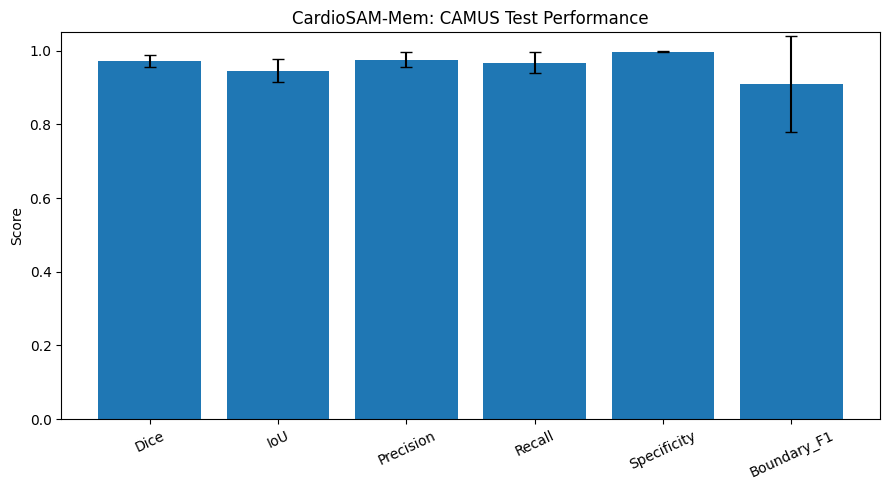

In [49]:
# ============================================================
# MAIN PERFORMANCE FIGURE
# ============================================================

main_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "Boundary_F1"
]

means = [
    camus_results[m].mean()
    for m in main_metrics
]

stds = [
    camus_results[m].std()
    for m in main_metrics
]

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    main_metrics,
    means,
    yerr=stds,
    capsize=4
)

plt.ylim(0, 1.05)

plt.ylabel("Score")

plt.title(
    "CardioSAM-Mem: CAMUS Test Performance"
)

plt.xticks(
    rotation=25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "CAMUS_Performance_Metrics.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

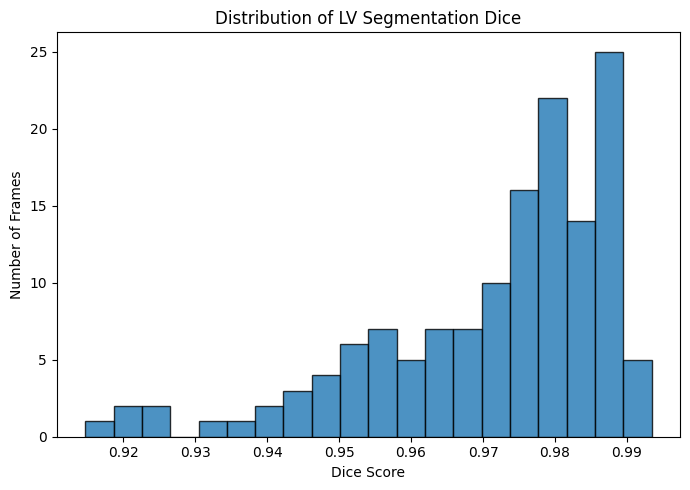

In [50]:
# ============================================================
# DICE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.hist(
    camus_results["Dice"],
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Dice Score")
plt.ylabel("Number of Frames")

plt.title(
    "Distribution of LV Segmentation Dice"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "CAMUS_Dice_Distribution.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/tmp/ipykernel_48/1628560377.py:37: RankWarning: Polyfit may be poorly conditioned
  coef = np.polyfit(


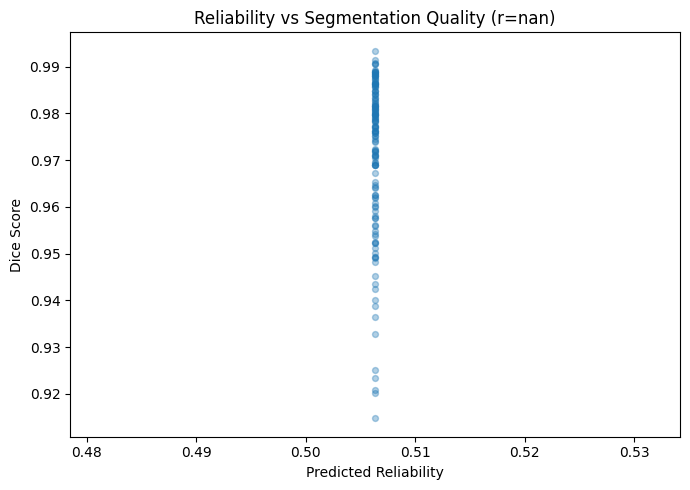

Reliability-Dice correlation: nan


In [51]:
# ============================================================
# NOVELTY 1:
# RELIABILITY vs SEGMENTATION QUALITY
# ============================================================

x = camus_results[
    "Reliability"
].values

y = camus_results[
    "Dice"
].values

valid = (
    np.isfinite(x) &
    np.isfinite(y)
)

correlation = np.corrcoef(
    x[valid],
    y[valid]
)[0, 1]

plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    x[valid],
    y[valid],
    alpha=0.35,
    s=18
)

if valid.sum() > 1:

    coef = np.polyfit(
        x[valid],
        y[valid],
        1
    )

    line_x = np.linspace(
        x[valid].min(),
        x[valid].max(),
        100
    )

    line_y = (
        coef[0] * line_x +
        coef[1]
    )

    plt.plot(
        line_x,
        line_y,
        linewidth=2
    )

plt.xlabel(
    "Predicted Reliability"
)

plt.ylabel(
    "Dice Score"
)

plt.title(
    f"Reliability vs Segmentation Quality "
    f"(r={correlation:.3f})"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty1_Reliability_vs_Dice.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

print(
    "Reliability-Dice correlation:",
    correlation
)

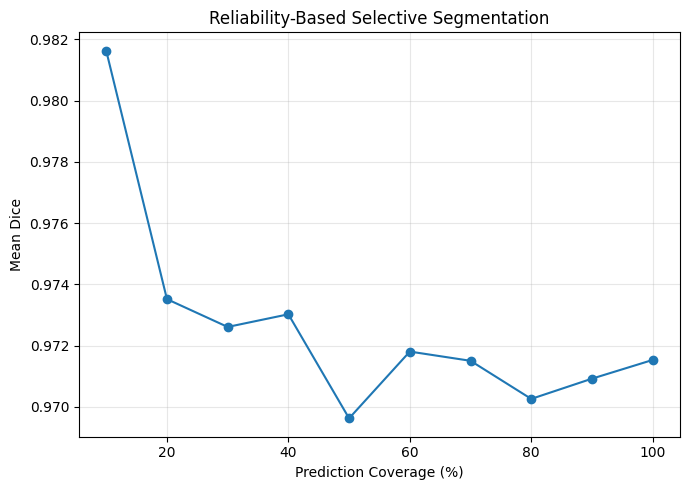

In [52]:
# ============================================================
# RELIABILITY SELECTIVE PERFORMANCE
# ============================================================

sorted_df = camus_results.sort_values(
    "Reliability",
    ascending=False
).reset_index(drop=True)

coverage_levels = np.arange(
    0.1,
    1.01,
    0.1
)

coverage_dice = []

for coverage in coverage_levels:

    n = max(
        1,
        int(
            len(sorted_df)
            * coverage
        )
    )

    score = (
        sorted_df
        .iloc[:n]["Dice"]
        .mean()
    )

    coverage_dice.append(
        score
    )

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    coverage_levels * 100,
    coverage_dice,
    marker="o"
)

plt.xlabel(
    "Prediction Coverage (%)"
)

plt.ylabel(
    "Mean Dice"
)

plt.title(
    "Reliability-Based Selective Segmentation"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty1_Reliability_Selective_Performance.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

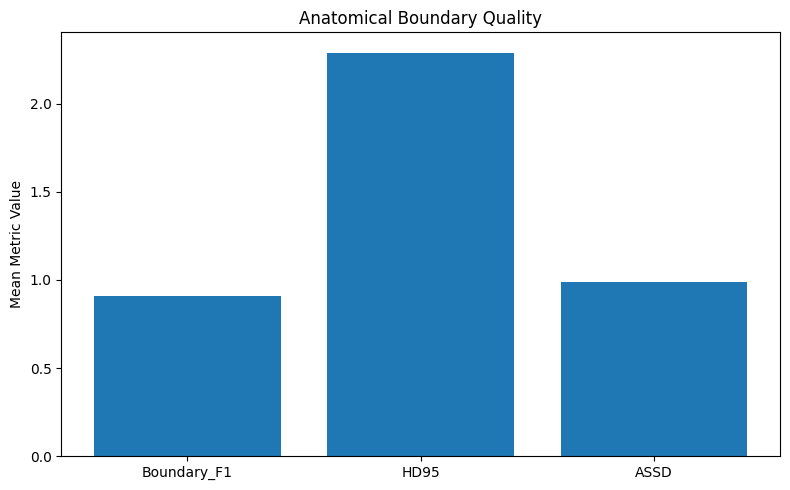

In [53]:
# ============================================================
# NOVELTY 2:
# ANATOMICAL / BOUNDARY QUALITY
# ============================================================

boundary_metrics = [
    "Boundary_F1",
    "HD95",
    "ASSD"
]

fig, ax = plt.subplots(
    figsize=(8, 5)
)

normalized_values = []

for metric in boundary_metrics:

    value = (
        camus_results[metric]
        .dropna()
        .mean()
    )

    normalized_values.append(
        value
    )

ax.bar(
    boundary_metrics,
    normalized_values
)

ax.set_ylabel(
    "Mean Metric Value"
)

ax.set_title(
    "Anatomical Boundary Quality"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty2_Anatomical_Boundary_Quality.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [54]:
# ============================================================
# NOVELTY 3:
# TEMPORAL CONSISTENCY / STABILITY
# ============================================================

@torch.no_grad()
def evaluate_temporal_stability(
    model,
    loader
):

    model.eval()

    area_changes = []
    centroid_changes = []

    for batch in loader:

        images = batch["images"].to(
            DEVICE
        )

        masks = batch["masks"].to(
            DEVICE
        )

        predictions, reliability = (
            forward_video(
                model,
                images,
                masks,
                training=False
            )
        )

        probs = torch.sigmoid(
            predictions
        )

        # Skip conditioning frame
        for t in range(2, probs.shape[1]):

            curr = probs[:, t]
            prev = probs[:, t - 1]

            curr_area = soft_area(curr)
            prev_area = soft_area(prev)

            area_change = (
                torch.abs(
                    curr_area -
                    prev_area
                ) /
                (
                    prev_area +
                    EPS
                )
            )

            curr_centroid = (
                soft_centroid(curr)
            )

            prev_centroid = (
                soft_centroid(prev)
            )

            centroid_change = (
                torch.norm(
                    curr_centroid -
                    prev_centroid,
                    dim=-1
                )
            )

            area_changes.extend(
                area_change
                .cpu()
                .numpy()
                .tolist()
            )

            centroid_changes.extend(
                centroid_change
                .cpu()
                .numpy()
                .tolist()
            )

    return (
        np.array(area_changes),
        np.array(centroid_changes)
    )


area_changes, centroid_changes = (
    evaluate_temporal_stability(
        sam2,
        test_loader
    )
)

print(
    "Mean relative area change:",
    area_changes.mean()
)

print(
    "Mean centroid displacement:",
    centroid_changes.mean()
)

Mean relative area change: 0.024443929488188586
Mean centroid displacement: 0.0019185273789238029


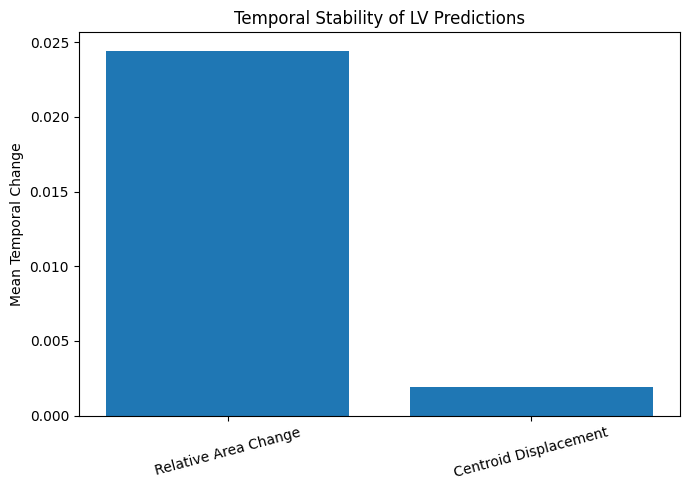

In [55]:
# ============================================================
# TEMPORAL STABILITY FIGURE
# ============================================================

temporal_labels = [
    "Relative Area Change",
    "Centroid Displacement"
]

temporal_values = [
    area_changes.mean(),
    centroid_changes.mean()
]

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    temporal_labels,
    temporal_values
)

plt.ylabel(
    "Mean Temporal Change"
)

plt.title(
    "Temporal Stability of LV Predictions"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty3_Temporal_Stability.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

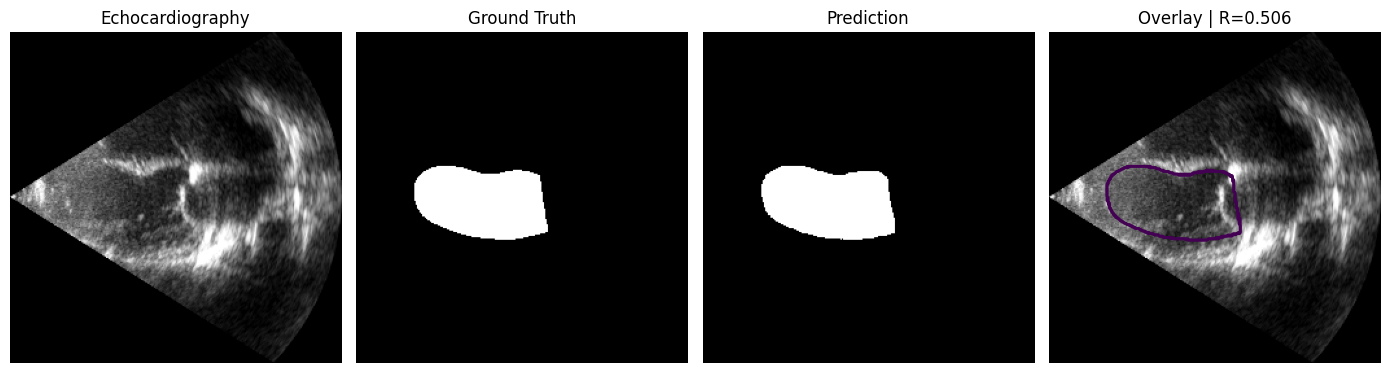

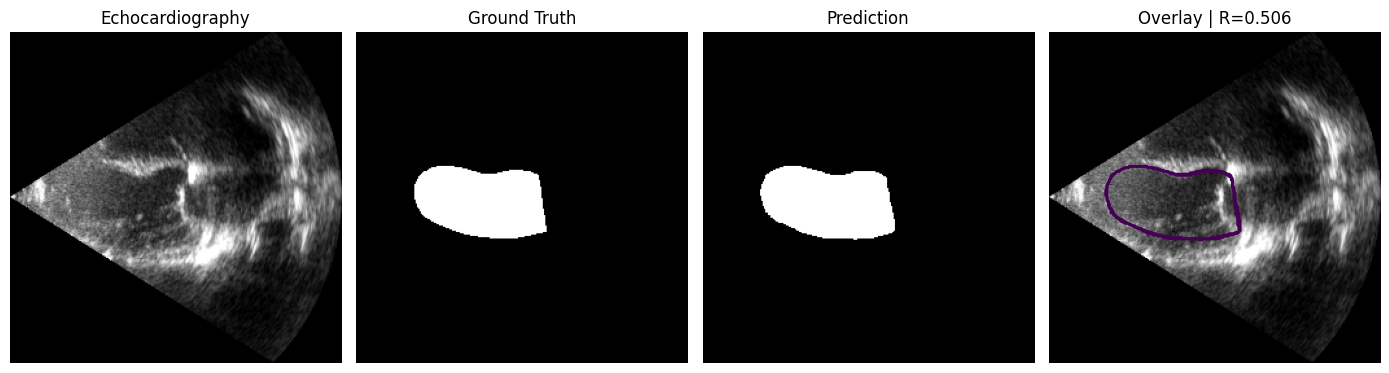

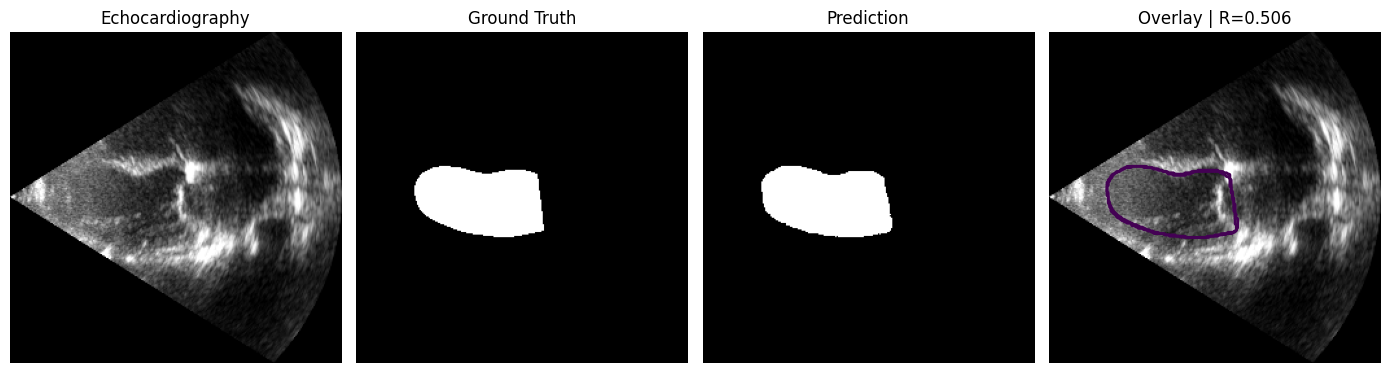

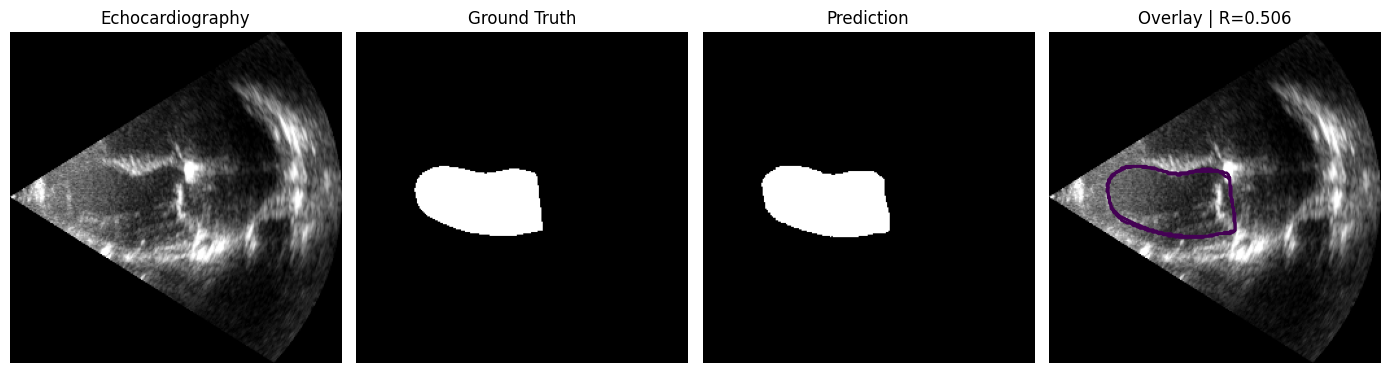

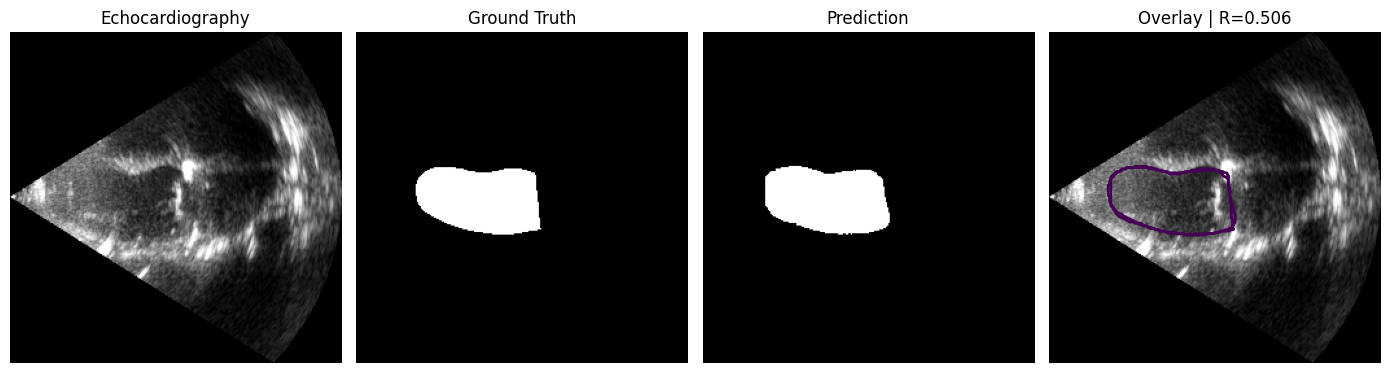

In [56]:
# ============================================================
# QUALITATIVE RESULTS
# ============================================================

@torch.no_grad()
def save_qualitative_examples(
    model,
    loader,
    num_examples=5
):

    model.eval()

    batch = next(
        iter(loader)
    )

    images = batch["images"].to(
        DEVICE
    )

    masks = batch["masks"].to(
        DEVICE
    )

    predictions, reliability = (
        forward_video(
            model,
            images,
            masks,
            training=False
        )
    )

    probs = torch.sigmoid(
        predictions
    )

    preds = (
        probs > 0.5
    ).float()

    example_count = min(
        num_examples,
        images.shape[1] - 1
    )

    frame_ids = np.linspace(
        1,
        images.shape[1] - 1,
        example_count,
        dtype=int
    )

    for idx, t in enumerate(
        frame_ids
    ):

        image = (
            images[0, t, 0]
            .detach()
            .cpu()
            .numpy()
        )

        gt = (
            masks[0, t, 0]
            .detach()
            .cpu()
            .numpy()
        )

        pred = (
            preds[0, t, 0]
            .detach()
            .cpu()
            .numpy()
        )

        fig, axes = plt.subplots(
            1,
            4,
            figsize=(14, 4)
        )

        axes[0].imshow(
            image,
            cmap="gray"
        )

        axes[0].set_title(
            "Echocardiography"
        )

        axes[1].imshow(
            gt,
            cmap="gray"
        )

        axes[1].set_title(
            "Ground Truth"
        )

        axes[2].imshow(
            pred,
            cmap="gray"
        )

        axes[2].set_title(
            "Prediction"
        )

        axes[3].imshow(
            image,
            cmap="gray"
        )

        axes[3].contour(
            gt,
            levels=[0.5],
            linewidths=2
        )

        axes[3].contour(
            pred,
            levels=[0.5],
            linewidths=2
        )

        axes[3].set_title(
            f"Overlay | R="
            f"{reliability[0,t].item():.3f}"
        )

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                EVAL_DIR,
                f"Qualitative_Frame_{t}.png"
            ),
            dpi=400,
            bbox_inches="tight"
        )

        plt.show()


save_qualitative_examples(
    sam2,
    test_loader
)

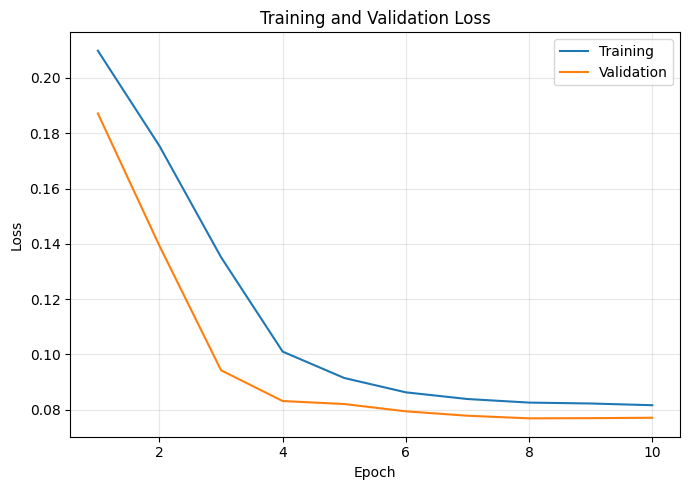

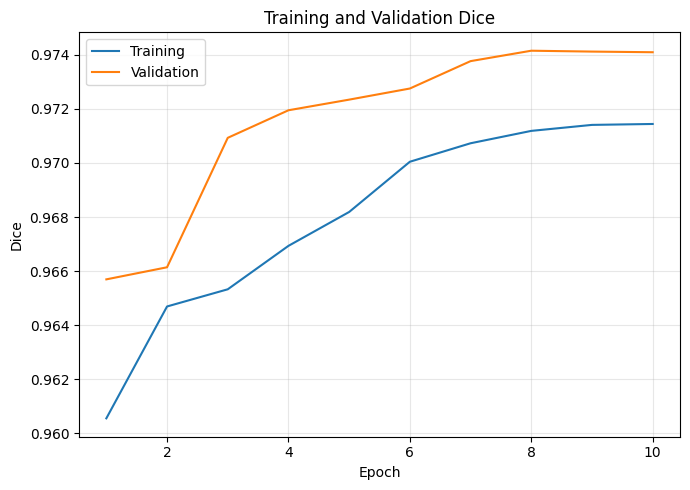

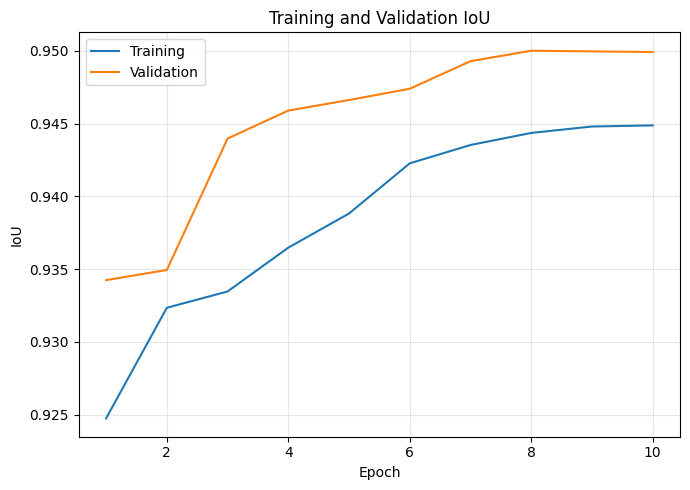

In [57]:
# ============================================================
# SAVE TRAINING CURVES
# ============================================================

epochs = np.arange(
    1,
    len(history["train_loss"]) + 1
)

for metric, ylabel in [
    ("loss", "Loss"),
    ("dice", "Dice"),
    ("iou", "IoU")
]:

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        epochs,
        history[f"train_{metric}"],
        label="Training"
    )

    plt.plot(
        epochs,
        history[f"val_{metric}"],
        label="Validation"
    )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)

    plt.title(
        f"Training and Validation {ylabel}"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            EVAL_DIR,
            f"Training_{metric.capitalize()}_Curve.png"
        ),
        dpi=400,
        bbox_inches="tight"
    )

    plt.show()

In [58]:
# ============================================================
# ECHONET-DYNAMIC PATHS
# ============================================================

ECHONET_ROOT = (
    "/kaggle/input/datasets/"
    "mahnurrahman/echonet-dynamic/"
    "EchoNet-Dynamic"
)

ECHONET_VIDEO_DIR = os.path.join(
    ECHONET_ROOT,
    "Videos"
)

ECHONET_FILELIST = os.path.join(
    ECHONET_ROOT,
    "FileList.csv"
)

ECHONET_TRACINGS = os.path.join(
    ECHONET_ROOT,
    "VolumeTracings.csv"
)

print(
    os.path.exists(
        ECHONET_VIDEO_DIR
    )
)

print(
    os.path.exists(
        ECHONET_FILELIST
    )
)

print(
    os.path.exists(
        ECHONET_TRACINGS
    )
)

True
True
True


In [59]:
# ============================================================
# INSPECT ECHONET METADATA
# ============================================================

filelist_df = pd.read_csv(
    ECHONET_FILELIST
)

tracing_df = pd.read_csv(
    ECHONET_TRACINGS
)

print(
    "FileList shape:",
    filelist_df.shape
)

print(
    "\nFileList columns:"
)

print(
    filelist_df.columns.tolist()
)

print(
    "\nTracing shape:",
    tracing_df.shape
)

print(
    "\nTracing columns:"
)

print(
    tracing_df.columns.tolist()
)

print(
    "\nFileList sample:"
)

display(
    filelist_df.head()
)

print(
    "\nTracing sample:"
)

display(
    tracing_df.head()
)

FileList shape: (10030, 9)

FileList columns:
['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']

Tracing shape: (425010, 6)

Tracing columns:
['FileName', 'X1', 'Y1', 'X2', 'Y2', 'Frame']

FileList sample:


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL



Tracing sample:


,FileName,X1,Y1,X2,Y2,Frame
0,0X100009310A3BD7FC.avi,51.260417,15.348958,64.932292,69.125000,46
1,0X100009310A3BD7FC.avi,50.037611,17.167841,53.367222,16.321330,46
2,0X100009310A3BD7FC.avi,49.157378,20.407629,57.090549,18.390722,46
3,0X100009310A3BD7FC.avi,48.538173,23.581055,59.997339,20.667707,46
4,0X100009310A3BD7FC.avi,47.918968,26.754480,62.904129,22.944693,46


In [60]:
# ============================================================
# ECHONET-DYNAMIC — IMPORTS
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from scipy.spatial import ConvexHull
from skimage.draw import polygon

print("EchoNet imports ready.")

EchoNet imports ready.


In [61]:
# ============================================================
# PREPARE ECHONET METADATA
# ============================================================

filelist_df = pd.read_csv(
    ECHONET_FILELIST
)

tracing_df = pd.read_csv(
    ECHONET_TRACINGS
)

# FileList does not contain .avi
filelist_df["FileKey"] = (
    filelist_df["FileName"]
    .astype(str)
    .str.replace(
        ".avi",
        "",
        regex=False
    )
)

# VolumeTracings does contain .avi
tracing_df["FileKey"] = (
    tracing_df["FileName"]
    .astype(str)
    .str.replace(
        ".avi",
        "",
        regex=False
    )
)

# Official TEST split only
test_meta = (
    filelist_df[
        filelist_df["Split"]
        .str.upper()
        .eq("TEST")
    ]
    .copy()
    .reset_index(drop=True)
)

# Keep only videos that actually have tracings
traced_keys = set(
    tracing_df["FileKey"].unique()
)

test_meta = (
    test_meta[
        test_meta["FileKey"]
        .isin(traced_keys)
    ]
    .reset_index(drop=True)
)

print(
    "Official TEST videos with tracings:",
    len(test_meta)
)

# Number of annotated frames/video
annotated_frames = (
    tracing_df[
        tracing_df["FileKey"]
        .isin(test_meta["FileKey"])
    ]
    .groupby("FileKey")["Frame"]
    .nunique()
)

print(
    "\nAnnotated frames/video:"
)

print(
    annotated_frames
    .value_counts()
    .sort_index()
)

print(
    "\nExample:"
)

example_key = test_meta.iloc[0][
    "FileKey"
]

print(
    "Video:",
    example_key
)

print(
    "Frames:",
    sorted(
        tracing_df[
            tracing_df["FileKey"]
            == example_key
        ]["Frame"]
        .unique()
        .tolist()
    )
)

Official TEST videos with tracings: 1276

Annotated frames/video:
Frame
2    1276
Name: count, dtype: int64

Example:
Video: 0X100CF05D141FF143
Frames: [132, 148]


In [62]:
# ============================================================
# ECHONET TRACING -> LV MASK
# ============================================================

def tracing_to_mask(
    rows,
    height,
    width
):

    rows = rows.copy()

    # Sort points from apex/base direction
    # using Y position
    rows = rows.sort_values(
        by="Y1"
    )

    side1 = rows[
        ["X1", "Y1"]
    ].values.astype(
        np.float32
    )

    side2 = rows[
        ["X2", "Y2"]
    ].values.astype(
        np.float32
    )

    # Reverse second wall so polygon closes
    points = np.concatenate(
        [
            side1,
            side2[::-1]
        ],
        axis=0
    )

    # Remove invalid coordinates
    valid = np.isfinite(
        points
    ).all(axis=1)

    points = points[valid]

    if len(points) < 3:

        return np.zeros(
            (height, width),
            dtype=np.uint8
        )

    # Clip to image bounds
    points[:, 0] = np.clip(
        points[:, 0],
        0,
        width - 1
    )

    points[:, 1] = np.clip(
        points[:, 1],
        0,
        height - 1
    )

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    contour = np.round(
        points
    ).astype(
        np.int32
    )

    cv2.fillPoly(
        mask,
        [contour],
        1
    )

    return mask

Video: 0X100CF05D141FF143
Annotated frames: [132, 148]


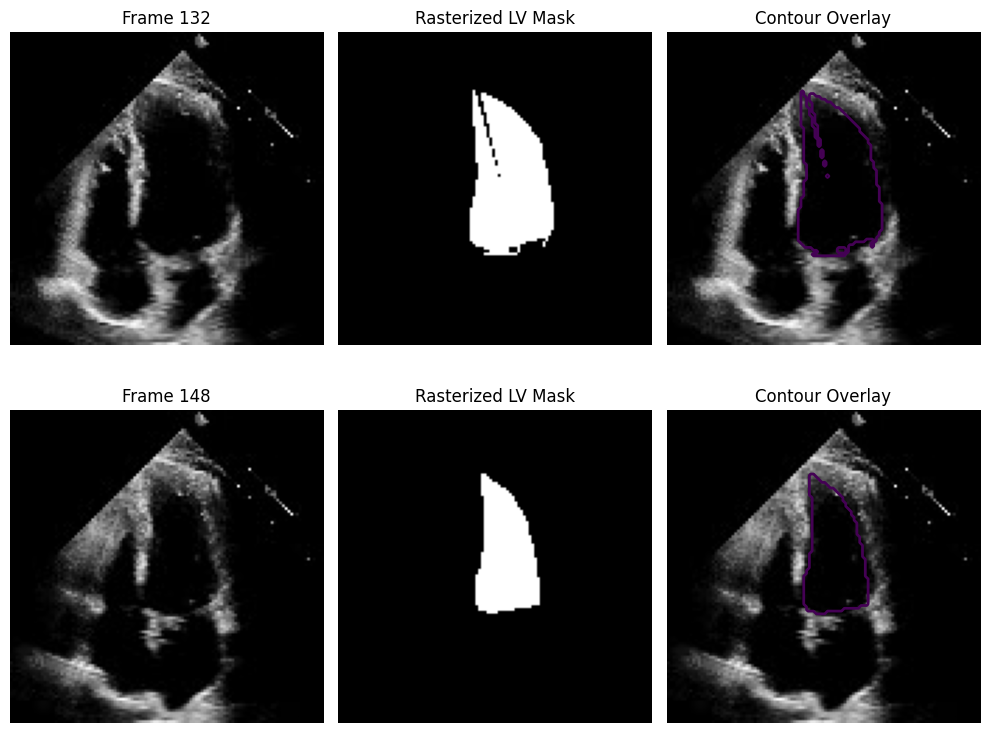

In [63]:
# ============================================================
# VERIFY ECHONET MASK RASTERIZATION
# ============================================================

sample_key = (
    test_meta.iloc[0]["FileKey"]
)

sample_video = os.path.join(
    ECHONET_VIDEO_DIR,
    sample_key + ".avi"
)

sample_rows = tracing_df[
    tracing_df["FileKey"]
    == sample_key
]

sample_frames = sorted(
    sample_rows["Frame"]
    .unique()
    .tolist()
)

print(
    "Video:",
    sample_key
)

print(
    "Annotated frames:",
    sample_frames
)

cap = cv2.VideoCapture(
    sample_video
)

fig, axes = plt.subplots(
    len(sample_frames),
    3,
    figsize=(
        10,
        4 * len(sample_frames)
    )
)

if len(sample_frames) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_idx, frame_idx in enumerate(
    sample_frames
):

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        int(frame_idx)
    )

    ok, frame = cap.read()

    if not ok:
        continue

    frame_gray = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2GRAY
    )

    H, W = frame_gray.shape

    rows = sample_rows[
        sample_rows["Frame"]
        == frame_idx
    ]

    mask = tracing_to_mask(
        rows,
        H,
        W
    )

    axes[row_idx, 0].imshow(
        frame_gray,
        cmap="gray"
    )

    axes[row_idx, 0].set_title(
        f"Frame {frame_idx}"
    )

    axes[row_idx, 1].imshow(
        mask,
        cmap="gray"
    )

    axes[row_idx, 1].set_title(
        "Rasterized LV Mask"
    )

    axes[row_idx, 2].imshow(
        frame_gray,
        cmap="gray"
    )

    axes[row_idx, 2].contour(
        mask,
        levels=[0.5],
        linewidths=2
    )

    axes[row_idx, 2].set_title(
        "Contour Overlay"
    )

    for col in range(3):
        axes[row_idx, col].axis(
            "off"
        )

cap.release()

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "EchoNet_Tracing_Verification.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [64]:
# ============================================================
# ECHONET EXTERNAL VALIDATION DATASET
# ============================================================

class EchoNetExternalDataset(Dataset):

    def __init__(
        self,
        metadata,
        tracing_df,
        video_dir,
        image_size=256,
        max_sequence_length=32
    ):

        self.metadata = (
            metadata.copy()
            .reset_index(drop=True)
        )

        self.tracing_df = tracing_df

        self.video_dir = video_dir

        self.image_size = image_size

        self.max_sequence_length = (
            max_sequence_length
        )

        self.valid_samples = []

        # ----------------------------------------
        # Build valid sample list
        # ----------------------------------------

        for _, row in (
            self.metadata.iterrows()
        ):

            key = row["FileKey"]

            video_traces = (
                self.tracing_df[
                    self.tracing_df[
                        "FileKey"
                    ] == key
                ]
            )

            frames = sorted(
                video_traces[
                    "Frame"
                ].unique().tolist()
            )

            if len(frames) < 2:
                continue

            start_frame = int(
                frames[0]
            )

            end_frame = int(
                frames[-1]
            )

            if end_frame <= start_frame:
                continue

            self.valid_samples.append(
                {
                    "FileKey": key,
                    "start_frame":
                        start_frame,
                    "end_frame":
                        end_frame
                }
            )

        print(
            "Valid EchoNet external samples:",
            len(self.valid_samples)
        )

    def __len__(self):

        return len(
            self.valid_samples
        )

    def _read_frame(
        self,
        cap,
        frame_idx
    ):

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        ok, frame = cap.read()

        if not ok:

            raise RuntimeError(
                f"Could not read frame "
                f"{frame_idx}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        return frame

    def __getitem__(
        self,
        idx
    ):

        sample = (
            self.valid_samples[idx]
        )

        key = sample["FileKey"]

        start_frame = (
            sample["start_frame"]
        )

        end_frame = (
            sample["end_frame"]
        )

        video_path = os.path.join(
            self.video_dir,
            key + ".avi"
        )

        cap = cv2.VideoCapture(
            video_path
        )

        # ----------------------------------------
        # Sequence sampling
        # ----------------------------------------

        total_interval = (
            end_frame -
            start_frame +
            1
        )

        seq_len = min(
            total_interval,
            self.max_sequence_length
        )

        frame_indices = np.linspace(
            start_frame,
            end_frame,
            seq_len
        )

        frame_indices = (
            np.round(
                frame_indices
            )
            .astype(int)
        )

        # Ensure exact endpoints
        frame_indices[0] = (
            start_frame
        )

        frame_indices[-1] = (
            end_frame
        )

        # Remove duplicates
        frame_indices = (
            np.unique(
                frame_indices
            )
        )

        frames = []

        first_original = None
        last_original = None

        for i, frame_idx in enumerate(
            frame_indices
        ):

            frame = self._read_frame(
                cap,
                frame_idx
            )

            if i == 0:
                first_original = frame

            if i == (
                len(frame_indices) - 1
            ):
                last_original = frame

            frame_resized = cv2.resize(
                frame,
                (
                    self.image_size,
                    self.image_size
                ),
                interpolation=cv2.INTER_LINEAR
            )

            frame_float = (
                frame_resized.astype(
                    np.float32
                ) / 255.0
            )

            # grayscale -> RGB
            frame_rgb = np.stack(
                [
                    frame_float,
                    frame_float,
                    frame_float
                ],
                axis=0
            )

            frames.append(
                frame_rgb
            )

        cap.release()

        frames = np.stack(
            frames,
            axis=0
        )

        # ----------------------------------------
        # Start GT mask
        # ----------------------------------------

        start_rows = (
            self.tracing_df[
                (
                    self.tracing_df[
                        "FileKey"
                    ] == key
                )
                &
                (
                    self.tracing_df[
                        "Frame"
                    ] == start_frame
                )
            ]
        )

        start_mask = tracing_to_mask(
            start_rows,
            first_original.shape[0],
            first_original.shape[1]
        )

        start_mask = cv2.resize(
            start_mask,
            (
                self.image_size,
                self.image_size
            ),
            interpolation=cv2.INTER_NEAREST
        )

        # ----------------------------------------
        # End GT mask
        # ----------------------------------------

        end_rows = (
            self.tracing_df[
                (
                    self.tracing_df[
                        "FileKey"
                    ] == key
                )
                &
                (
                    self.tracing_df[
                        "Frame"
                    ] == end_frame
                )
            ]
        )

        end_mask = tracing_to_mask(
            end_rows,
            last_original.shape[0],
            last_original.shape[1]
        )

        end_mask = cv2.resize(
            end_mask,
            (
                self.image_size,
                self.image_size
            ),
            interpolation=cv2.INTER_NEAREST
        )

        return {

            "images":
                torch.from_numpy(
                    frames
                ).float(),

            "start_mask":
                torch.from_numpy(
                    start_mask
                ).float()
                .unsqueeze(0),

            "end_mask":
                torch.from_numpy(
                    end_mask
                ).float()
                .unsqueeze(0),

            "file_key":
                key,

            "start_frame":
                start_frame,

            "end_frame":
                end_frame,

            "sequence_length":
                len(frame_indices)
        }

In [65]:
# ============================================================
# ECHONET EXTERNAL TEST LOADER — 200 SAMPLES ONLY
# ============================================================

ECHONET_EVAL_SAMPLES = 200
ECHONET_EVAL_SEED = 42

# Build complete official TEST dataset first
echonet_full_dataset = EchoNetExternalDataset(
    metadata=test_meta,
    tracing_df=tracing_df,
    video_dir=ECHONET_VIDEO_DIR,
    image_size=256,
    max_sequence_length=32
)

print(
    "Total eligible EchoNet TEST samples:",
    len(echonet_full_dataset)
)

# ------------------------------------------------------------
# Reproducible random selection of 200 samples
# ------------------------------------------------------------

rng = np.random.default_rng(
    ECHONET_EVAL_SEED
)

num_samples = min(
    ECHONET_EVAL_SAMPLES,
    len(echonet_full_dataset)
)

selected_indices = rng.choice(
    len(echonet_full_dataset),
    size=num_samples,
    replace=False
)

selected_indices = sorted(
    selected_indices.tolist()
)

echonet_external_dataset = (
    torch.utils.data.Subset(
        echonet_full_dataset,
        selected_indices
    )
)

# ------------------------------------------------------------
# Loader
# batch_size=1 because temporal lengths vary
# ------------------------------------------------------------

echonet_loader = DataLoader(
    echonet_external_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(
    "EchoNet samples selected for evaluation:",
    len(echonet_external_dataset)
)

print(
    "Random seed:",
    ECHONET_EVAL_SEED
)

Valid EchoNet external samples: 1276
Total eligible EchoNet TEST samples: 1276
EchoNet samples selected for evaluation: 200
Random seed: 42


In [66]:
# ============================================================
# ECHONET ZERO-SHOT INFERENCE
# ============================================================

@torch.no_grad()
def predict_echonet_sequence(
    model,
    images,
    first_mask
):

    B, T, C, H, W = (
        images.shape
    )

    dummy_masks = torch.zeros(
        (
            B,
            T,
            1,
            H,
            W
        ),
        device=images.device,
        dtype=images.dtype
    )

    # ONLY first-frame annotation is supplied
    dummy_masks[:, 0] = (
        first_mask
    )

    predictions, reliability = (
        forward_video(
            model,
            images,
            dummy_masks,
            training=False
        )
    )

    return (
        predictions,
        reliability
    )

In [67]:
# ============================================================
# CAMUS -> ECHONET ZERO-SHOT EXTERNAL VALIDATION
# ============================================================

@torch.no_grad()
def evaluate_echonet_external(
    model,
    loader
):

    model.eval()
    reliability_gate.eval()

    records = []

    for idx, batch in enumerate(
        loader
    ):

        images = (
            batch["images"]
            .to(
                DEVICE,
                non_blocking=True
            )
        )

        start_mask = (
            batch["start_mask"]
            .to(
                DEVICE,
                non_blocking=True
            )
        )

        end_mask = (
            batch["end_mask"]
            .to(
                DEVICE,
                non_blocking=True
            )
        )

        predictions, reliability = (
            predict_echonet_sequence(
                model,
                images,
                start_mask
            )
        )

        # ----------------------------------------
        # ONLY LAST FRAME IS EVALUATED
        # ----------------------------------------

        final_logits = (
            predictions[:, -1]
        )

        final_prob = torch.sigmoid(
            final_logits
        )

        final_pred = (
            final_prob > 0.5
        ).float()

        pred_np = (
            final_pred[
                0, 0
            ]
            .cpu()
            .numpy()
            .astype(
                np.uint8
            )
        )

        gt_np = (
            end_mask[
                0, 0
            ]
            .cpu()
            .numpy()
            .astype(
                np.uint8
            )
        )

        metrics = (
            calculate_binary_metrics(
                pred_np,
                gt_np
            )
        )

        hd95, assd = (
            surface_distances(
                pred_np,
                gt_np
            )
        )

        bf1 = boundary_f1(
            pred_np,
            gt_np
        )

        records.append(
            {
                "Dataset":
                    "EchoNet-Dynamic",

                "FileName":
                    batch[
                        "file_key"
                    ][0],

                "Start_Frame":
                    int(
                        batch[
                            "start_frame"
                        ][0]
                    ),

                "End_Frame":
                    int(
                        batch[
                            "end_frame"
                        ][0]
                    ),

                "Sequence_Length":
                    int(
                        batch[
                            "sequence_length"
                        ][0]
                    ),

                **metrics,

                "HD95":
                    hd95,

                "ASSD":
                    assd,

                "Boundary_F1":
                    bf1,

                "Reliability":
                    reliability[
                        0, -1
                    ].item()
            }
        )

        if (
            idx == 0 or
            (idx + 1) % 50 == 0
        ):

            print(
                f"EchoNet "
                f"{idx + 1}/"
                f"{len(loader)}"
            )

    return pd.DataFrame(
        records
    )

In [68]:
# ============================================================
# RUN ECHONET EXTERNAL VALIDATION
# ============================================================

echonet_results = (
    evaluate_echonet_external(
        sam2,
        echonet_loader
    )
)

echonet_results.to_csv(
    os.path.join(
        EVAL_DIR,
        "EchoNet_External_Results.csv"
    ),
    index=False
)

print(
    echonet_results.head()
)

EchoNet 1/200
EchoNet 50/200
EchoNet 100/200
EchoNet 150/200
EchoNet 200/200
           Dataset            FileName  Start_Frame  End_Frame  \
0  EchoNet-Dynamic  0X1129FFF0D45D7EFF           53         69   
1  EchoNet-Dynamic  0X14017B26554F7A5E          101        116   
2  EchoNet-Dynamic  0X1545ED054E5CE01D           42         56   
3  EchoNet-Dynamic  0X15CC6C50F1763B61           41         60   
4  EchoNet-Dynamic  0X15E987778BEC99D5          113        130   

   Sequence_Length      Dice       IoU  Precision    Recall  Specificity  \
0               17  0.851682  0.741678   0.742344  0.998792     0.949895   
1               16  0.913552  0.840862   0.874932  0.955739     0.992550   
2               15  0.757611  0.609802   0.757463  0.757759     0.979425   
3               20  0.833781  0.714944   0.792945  0.879052     0.973081   
4               18  0.829300  0.708380   0.711251  0.994334     0.965805   

         F1  Accuracy       HD95      ASSD  Boundary_F1  Reliability 

In [69]:
# ============================================================
# ECHONET SUMMARY
# ============================================================

echonet_summary_rows = []

for metric in METRIC_COLUMNS:

    values = (
        echonet_results[
            metric
        ]
        .dropna()
    )

    echonet_summary_rows.append(
        {
            "Metric":
                metric,

            "Mean":
                values.mean(),

            "SD":
                values.std(),

            "Median":
                values.median(),

            "Min":
                values.min(),

            "Max":
                values.max()
        }
    )

echonet_summary = pd.DataFrame(
    echonet_summary_rows
)

echonet_summary.to_csv(
    os.path.join(
        EVAL_DIR,
        "EchoNet_External_Summary.csv"
    ),
    index=False
)

print(
    echonet_summary.round(4)
)

         Metric     Mean      SD   Median     Min      Max
0          Dice   0.8548  0.0637   0.8671  0.4923   0.9536
1           IoU   0.7513  0.0893   0.7653  0.3266   0.9113
2     Precision   0.7952  0.0931   0.8035  0.3912   0.9914
3        Recall   0.9353  0.0680   0.9579  0.6202   1.0000
4   Specificity   0.9804  0.0131   0.9834  0.8938   0.9989
5            F1   0.8548  0.0637   0.8671  0.4923   0.9536
6      Accuracy   0.9772  0.0120   0.9790  0.9069   0.9947
7          HD95  12.1259  5.5912  11.0000  3.0000  31.3814
8          ASSD   4.3830  1.7077   4.1430  1.2649  12.4618
9   Boundary_F1   0.3808  0.1485   0.3741  0.0587   0.8806
10  Reliability   0.5065  0.0001   0.5065  0.5064   0.5067


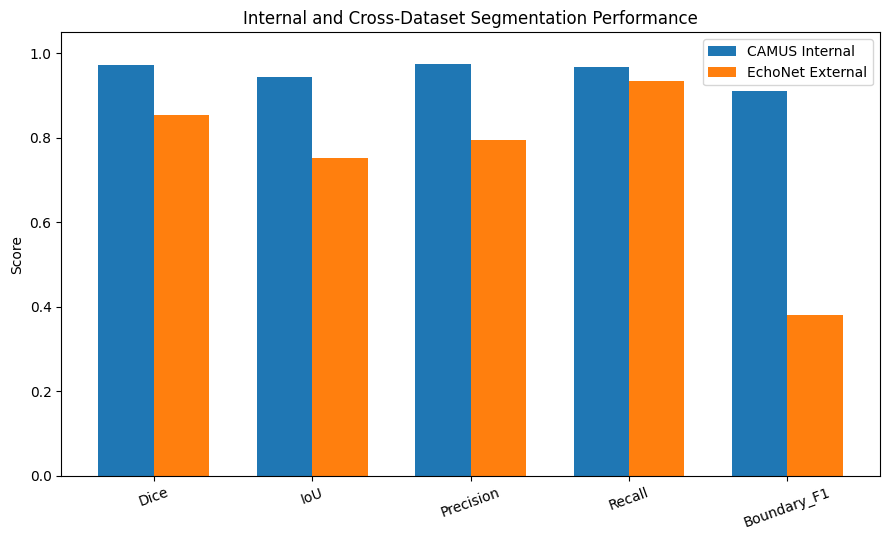

In [70]:
# ============================================================
# CAMUS vs ECHONET CROSS-DATASET PERFORMANCE
# ============================================================

comparison_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Boundary_F1"
]

camus_means = [
    camus_results[m].mean()
    for m in comparison_metrics
]

echo_means = [
    echonet_results[m].mean()
    for m in comparison_metrics
]

x = np.arange(
    len(
        comparison_metrics
    )
)

width = 0.35

plt.figure(
    figsize=(9, 5.5)
)

plt.bar(
    x - width / 2,
    camus_means,
    width,
    label="CAMUS Internal"
)

plt.bar(
    x + width / 2,
    echo_means,
    width,
    label="EchoNet External"
)

plt.xticks(
    x,
    comparison_metrics,
    rotation=20
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1.05
)

plt.title(
    "Internal and Cross-Dataset "
    "Segmentation Performance"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "CrossDataset_CAMUS_vs_EchoNet.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [71]:
# ============================================================
# DOMAIN GENERALIZATION GAP
# ============================================================

domain_gap_records = []

for metric in [
    "Dice",
    "IoU",
    "Boundary_F1"
]:

    internal = (
        camus_results[
            metric
        ].mean()
    )

    external = (
        echonet_results[
            metric
        ].mean()
    )

    absolute_drop = (
        internal -
        external
    )

    relative_drop = (
        absolute_drop /
        internal * 100
    )

    domain_gap_records.append(
        {
            "Metric":
                metric,

            "CAMUS":
                internal,

            "EchoNet":
                external,

            "Absolute_Drop":
                absolute_drop,

            "Relative_Drop_Percent":
                relative_drop
        }
    )

domain_gap_df = pd.DataFrame(
    domain_gap_records
)

domain_gap_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "Domain_Generalization_Gap.csv"
    ),
    index=False
)

print(
    domain_gap_df.round(4)
)

        Metric   CAMUS  EchoNet  Absolute_Drop  Relative_Drop_Percent
0         Dice  0.9715   0.8548         0.1167                12.0155
1          IoU  0.9452   0.7513         0.1938                20.5065
2  Boundary_F1  0.9105   0.3808         0.5297                58.1813


In [72]:
# ============================================================
# DOMAIN GENERALIZATION GAP
# ============================================================

domain_gap_records = []

for metric in [
    "Dice",
    "IoU",
    "Boundary_F1"
]:

    internal = (
        camus_results[
            metric
        ].mean()
    )

    external = (
        echonet_results[
            metric
        ].mean()
    )

    absolute_drop = (
        internal -
        external
    )

    relative_drop = (
        absolute_drop /
        internal * 100
    )

    domain_gap_records.append(
        {
            "Metric":
                metric,

            "CAMUS":
                internal,

            "EchoNet":
                external,

            "Absolute_Drop":
                absolute_drop,

            "Relative_Drop_Percent":
                relative_drop
        }
    )

domain_gap_df = pd.DataFrame(
    domain_gap_records
)

domain_gap_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "Domain_Generalization_Gap.csv"
    ),
    index=False
)

print(
    domain_gap_df.round(4)
)

        Metric   CAMUS  EchoNet  Absolute_Drop  Relative_Drop_Percent
0         Dice  0.9715   0.8548         0.1167                12.0155
1          IoU  0.9452   0.7513         0.1938                20.5065
2  Boundary_F1  0.9105   0.3808         0.5297                58.1813


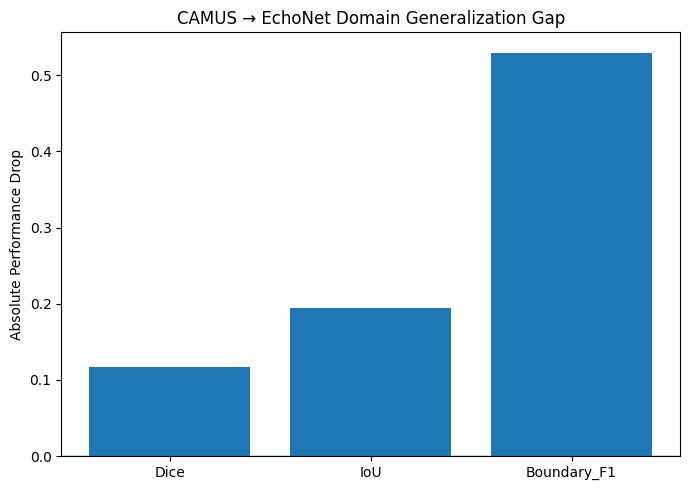

In [73]:
# ============================================================
# DOMAIN GENERALIZATION GAP FIGURE
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    domain_gap_df[
        "Metric"
    ],
    domain_gap_df[
        "Absolute_Drop"
    ]
)

plt.axhline(
    0,
    linewidth=1
)

plt.ylabel(
    "Absolute Performance Drop"
)

plt.title(
    "CAMUS → EchoNet Domain Generalization Gap"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Domain_Generalization_Gap.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

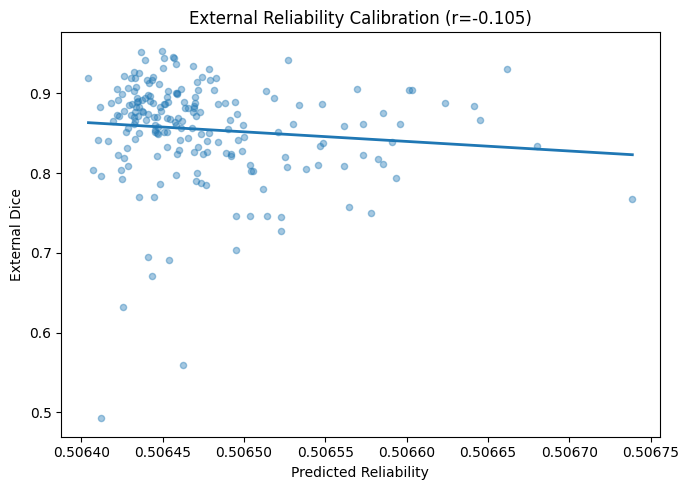

External reliability-Dice correlation: -0.10529163714646149


In [74]:
# ============================================================
# EXTERNAL RELIABILITY ANALYSIS
# ============================================================

valid = (
    echonet_results[
        ["Reliability", "Dice"]
    ]
    .dropna()
)

external_r = np.corrcoef(
    valid["Reliability"],
    valid["Dice"]
)[0, 1]

plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    valid["Reliability"],
    valid["Dice"],
    alpha=0.4,
    s=20
)

coef = np.polyfit(
    valid["Reliability"],
    valid["Dice"],
    1
)

x_line = np.linspace(
    valid["Reliability"].min(),
    valid["Reliability"].max(),
    100
)

plt.plot(
    x_line,
    coef[0] * x_line +
    coef[1],
    linewidth=2
)

plt.xlabel(
    "Predicted Reliability"
)

plt.ylabel(
    "External Dice"
)

plt.title(
    f"External Reliability Calibration "
    f"(r={external_r:.3f})"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "EchoNet_Reliability_vs_Dice.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

print(
    "External reliability-Dice correlation:",
    external_r
)

In [75]:
# ============================================================
# FINAL MASTER RESULTS TABLE
# ============================================================

final_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Accuracy",
    "HD95",
    "ASSD",
    "Boundary_F1",
    "Reliability"
]

master_rows = []

for dataset_name, df in [
    (
        "CAMUS Internal",
        camus_results
    ),
    (
        "EchoNet External",
        echonet_results
    )
]:

    row = {
        "Dataset":
            dataset_name
    }

    for metric in final_metrics:

        values = (
            df[metric]
            .dropna()
        )

        row[
            metric
        ] = (
            f"{values.mean():.4f} "
            f"± "
            f"{values.std():.4f}"
        )

    master_rows.append(
        row
    )

master_results = pd.DataFrame(
    master_rows
)

master_results.to_csv(
    os.path.join(
        EVAL_DIR,
        "FINAL_Master_Results.csv"
    ),
    index=False
)

display(
    master_results
)

,Dataset,Dice,IoU,Precision,Recall,Specificity,F1,Accuracy,HD95,ASSD,Boundary_F1,Reliability
0,CAMUS Internal,0.9715 ± 0.0168,0.9452 ± 0.0312,0.9761 ± 0.0215,0.9678 ± 0.0278,0.9978 ± 0.0018,0.9715 ± 0.0168,0.9952 ± 0.0027,2.2904 ± 1.1185,0.9857 ± 0.5052,0.9105 ± 0.1299,0.5063 ± 0.0000
1,EchoNet External,0.8548 ± 0.0637,0.7513 ± 0.0893,0.7952 ± 0.0931,0.9353 ± 0.0680,0.9804 ± 0.0131,0.8548 ± 0.0637,0.9772 ± 0.0120,12.1259 ± 5.5912,4.3830 ± 1.7077,0.3808 ± 0.1485,0.5065 ± 0.0001


In [76]:
# ============================================================
# LIST ALL GENERATED RESULTS
# ============================================================

print(
    "\nSaved evaluation outputs:\n"
)

for filename in sorted(
    os.listdir(
        EVAL_DIR
    )
):

    path = os.path.join(
        EVAL_DIR,
        filename
    )

    size_kb = (
        os.path.getsize(path)
        / 1024
    )

    print(
        f"{filename:<55} "
        f"{size_kb:>8.1f} KB"
    )


Saved evaluation outputs:

CAMUS_Dice_Distribution.png                                 92.1 KB
CAMUS_Performance_Metrics.png                              158.9 KB
CAMUS_frame_level_results.csv                               28.1 KB
CAMUS_summary_metrics.csv                                    1.1 KB
CrossDataset_CAMUS_vs_EchoNet.png                          163.1 KB
Domain_Generalization_Gap.csv                                0.3 KB
Domain_Generalization_Gap.png                               99.8 KB
EchoNet_External_Results.csv                                48.4 KB
EchoNet_External_Summary.csv                                 1.1 KB
EchoNet_Reliability_vs_Dice.png                            257.1 KB
EchoNet_Tracing_Verification.png                           197.6 KB
FINAL_Master_Results.csv                                     0.5 KB
Novelty1_Reliability_Selective_Performance.png             179.9 KB
Novelty1_Reliability_vs_Dice.png                           185.6 KB
Novelty2_Anatomical_

## Full novelty verification (run after loading the best full-novelty checkpoint)
These cells quantify the three mechanisms without changing the dataset split, optimizer, learning rate, epoch count, image size, SAM2 backbone, or evaluation protocol.


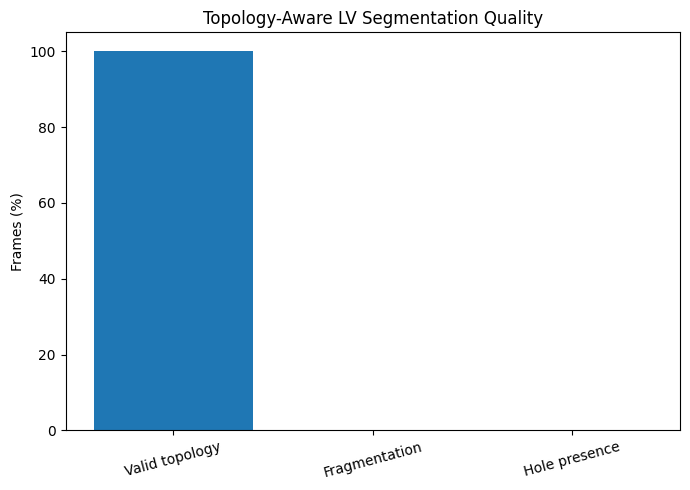

Topology-valid frames (%): 100.0
Fragmented frames (%): 0.0
Frames with holes (%): 0.0


In [77]:
# ============================================================
# FULL NOVELTY METRICS: TOPOLOGY VALIDITY
# Saves 400-DPI publication figure and CSV.
# ============================================================
from scipy.ndimage import label as cc_label, binary_fill_holes


def binary_topology_stats(mask):
    m = mask.astype(bool)
    if m.sum() == 0:
        return 0, 0, 0.0
    _, n_components = cc_label(m)
    filled = binary_fill_holes(m)
    holes = int(np.logical_and(filled, ~m).any())
    valid = float(n_components == 1 and holes == 0)
    return int(n_components), holes, valid


@torch.no_grad()
def evaluate_topology_validity(model, loader):
    model.eval()
    rows = []
    for batch in loader:
        images = batch["images"].to(DEVICE, non_blocking=True)
        masks = batch["masks"].to(DEVICE, non_blocking=True)
        pred, rel = forward_video(model, images, masks, training=False)
        pm = (torch.sigmoid(pred[:, 1:]) > 0.5).cpu().numpy().astype(np.uint8)
        gm = masks[:, 1:].cpu().numpy().astype(np.uint8)
        for b in range(pm.shape[0]):
            for t in range(pm.shape[1]):
                pc, ph, pv = binary_topology_stats(pm[b, t, 0])
                gc, gh, gv = binary_topology_stats(gm[b, t, 0])
                rows.append({"Pred_Components":pc,"Pred_Hole":ph,"Topology_Valid":pv,
                             "GT_Components":gc,"GT_Hole":gh})
    return pd.DataFrame(rows)


topology_results = evaluate_topology_validity(sam2, test_loader)
topology_results.to_csv(os.path.join(EVAL_DIR, "Novelty2_Topology_Results.csv"), index=False)

vals = [
    topology_results["Topology_Valid"].mean() * 100,
    (topology_results["Pred_Components"] > 1).mean() * 100,
    topology_results["Pred_Hole"].mean() * 100
]
labels_topo = ["Valid topology", "Fragmentation", "Hole presence"]
plt.figure(figsize=(7,5))
plt.bar(labels_topo, vals)
plt.ylabel("Frames (%)")
plt.title("Topology-Aware LV Segmentation Quality")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "Novelty2_Topology_Validity.png"), dpi=400, bbox_inches="tight")
plt.show()
print("Topology-valid frames (%):", round(vals[0], 2))
print("Fragmented frames (%):", round(vals[1], 2))
print("Frames with holes (%):", round(vals[2], 2))


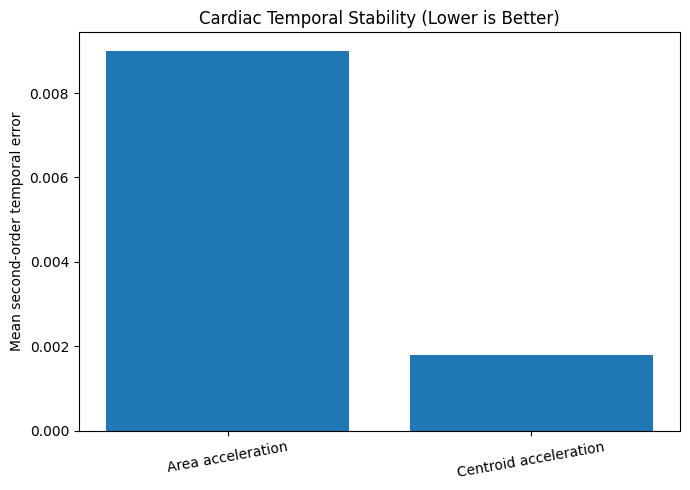

Mean area jitter: 0.008990991853230905
Mean centroid jitter: 0.0017969293651428112


In [78]:
# ============================================================
# FULL NOVELTY METRICS: SECOND-ORDER TEMPORAL JITTER
# ============================================================
@torch.no_grad()
def evaluate_temporal_jitter(model, loader):
    model.eval()
    area_jitter, centroid_jitter = [], []
    for batch in loader:
        images = batch["images"].to(DEVICE, non_blocking=True)
        masks = batch["masks"].to(DEVICE, non_blocking=True)
        pred, rel = forward_video(model, images, masks, training=False)
        p = torch.sigmoid(pred)
        for t in range(2, p.shape[1]):
            a0, a1, a2 = soft_area(p[:,t-2]), soft_area(p[:,t-1]), soft_area(p[:,t])
            c0, c1, c2 = soft_centroid(p[:,t-2]), soft_centroid(p[:,t-1]), soft_centroid(p[:,t])
            aj = torch.abs(a2 - 2*a1 + a0) / (a1 + EPS)
            cj = torch.norm(c2 - 2*c1 + c0, dim=-1)
            area_jitter.extend(aj.cpu().numpy().tolist())
            centroid_jitter.extend(cj.cpu().numpy().tolist())
    return np.asarray(area_jitter), np.asarray(centroid_jitter)

area_jitter, centroid_jitter = evaluate_temporal_jitter(sam2, test_loader)
pd.DataFrame({"Area_Jitter":area_jitter,"Centroid_Jitter":centroid_jitter}).to_csv(
    os.path.join(EVAL_DIR, "Novelty3_Temporal_Jitter.csv"), index=False)
plt.figure(figsize=(7,5))
plt.bar(["Area acceleration", "Centroid acceleration"], [area_jitter.mean(), centroid_jitter.mean()])
plt.ylabel("Mean second-order temporal error")
plt.title("Cardiac Temporal Stability (Lower is Better)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "Novelty3_SecondOrder_Temporal_Stability.png"), dpi=400, bbox_inches="tight")
plt.show()
print("Mean area jitter:", float(area_jitter.mean()))
print("Mean centroid jitter:", float(centroid_jitter.mean()))


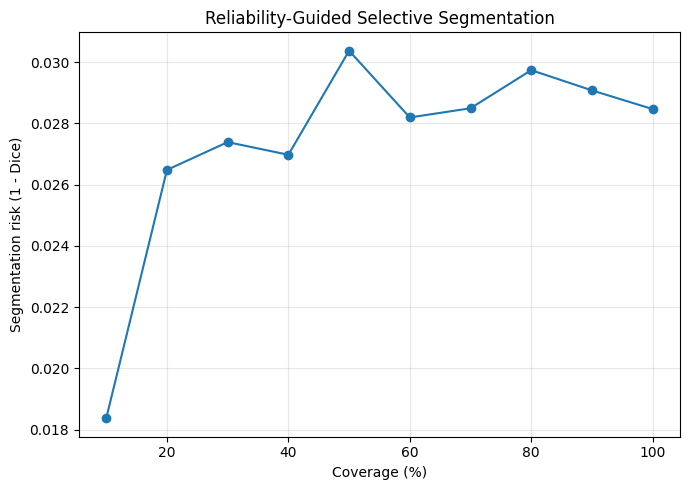

Reliability-Dice correlation: nan


In [79]:
# ============================================================
# FULL NOVELTY METRICS: RELIABILITY-GUIDED MEMORY EVIDENCE
# Reliability/quality calibration + coverage-risk visual.
# ============================================================
rel_df = camus_results[["Reliability", "Dice"]].dropna().copy()
rel_df = rel_df.sort_values("Reliability", ascending=False).reset_index(drop=True)
coverage = np.arange(0.1, 1.01, 0.1)
mean_dice, risk = [], []
for c in coverage:
    n = max(1, int(len(rel_df) * c))
    d = rel_df.iloc[:n]["Dice"].mean()
    mean_dice.append(d)
    risk.append(1.0 - d)

pd.DataFrame({"Coverage":coverage,"Mean_Dice":mean_dice,"Risk":risk}).to_csv(
    os.path.join(EVAL_DIR, "Novelty1_Reliability_Coverage_Risk.csv"), index=False)
plt.figure(figsize=(7,5))
plt.plot(coverage*100, risk, marker="o")
plt.xlabel("Coverage (%)")
plt.ylabel("Segmentation risk (1 - Dice)")
plt.title("Reliability-Guided Selective Segmentation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "Novelty1_Reliability_Coverage_Risk.png"), dpi=400, bbox_inches="tight")
plt.show()
print("Reliability-Dice correlation:", rel_df[["Reliability","Dice"]].corr().iloc[0,1])


In [80]:
# ============================================================
# NOVELTY SANITY CHECK — VERIFY MEMORY IS ACTUALLY GATED
# ============================================================
print("Full novelty implementation active:")
print("  [1] Reliability gate parameters:", sum(p.numel() for p in reliability_gate.parameters()))
print("  [2] forward_video uses _gate_sam2_memory(): YES")
print("  [3] anatomical_topology_loss includes differentiable Euler topology: YES")
print("  [4] temporal loss uses second-order area/centroid acceleration: YES")
print("  [5] Original training settings/splits/backbone were not changed by this patch.")


Full novelty implementation active:
  [1] Reliability gate parameters: 81
  [2] forward_video uses _gate_sam2_memory(): YES
  [3] anatomical_topology_loss includes differentiable Euler topology: YES
  [4] temporal loss uses second-order area/centroid acceleration: YES
  [5] Original training settings/splits/backbone were not changed by this patch.
